In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from time import time

# Import all models
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasRegressor

# Import all tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance

# Set warnings to ignore
warnings.filterwarnings('ignore')
print("All libraries imported successfully.")

All libraries imported successfully.


In [12]:
# --- 1. Load Data ---
# Use the v3 dataset that includes the HOMO-LUMO Gap
df = pd.read_csv("../data/final_model_dataset_v3.csv")
print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")

# --- 2. Define Features (X) and Target (y) ---
ignore_cols = ["cation", "cation_ion_name", "anion", "anion_ion_name"]
target_col = "CO2_solubility"

# We will train the models on ALL available features
feature_cols = [col for col in df.columns if col not in ignore_cols + [target_col]]
X = df[feature_cols]
y = df[target_col].values
print(f"Training models using all {len(feature_cols)} features.")

# --- 3. Split and Scale Data ---
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
print("Data preparation complete.")

Dataset loaded with 11256 rows and 253 columns.
Training models using all 248 features.
Data preparation complete.


In [15]:
# --- This cell defines all 4 models so we can train them ---

def create_model(meta):
    n_features_in_ = meta["n_features_in_"]
    model = keras.Sequential([
        layers.Input(shape=(n_features_in_,)),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Neural Network": KerasRegressor(model=create_model, epochs=100, batch_size=32, verbose=0)
}
print(f"Initialized {len(models)} models.")

Initialized 4 models.


In [16]:
# We must train all models on the full feature set before we can analyze them
print("--- Starting Model Training (on ALL features) ---")
for name, model in models.items():
    print(f"Training {name}...")
    start_time = time()
    model.fit(X_train_scaled, y_train)
    train_time = time() - start_time
    print(f"  > Done in {train_time:.2f}s")
print("\n--- All models trained. ---")

--- Starting Model Training (on ALL features) ---
Training Ridge Regression...
  > Done in 0.02s
Training Random Forest...
  > Done in 0.98s
Training Gradient Boosting...
  > Done in 1.08s
Training Neural Network...
  > Done in 19.44s

--- All models trained. ---


In [17]:
# Now we calculate the importance for all 240+ features for every model
print("\n--- Calculating Feature Importance for all models (this will take a few minutes)... ---")
importance_results = {}

for name, model in models.items():
    print(f"Calculating for {name}...")
    perm_importance = permutation_importance(
        model, X_val_scaled, y_val, 
        n_repeats=10, random_state=42, n_jobs=-1
    )
    importance_results[name] = perm_importance.importances_mean

# Create a DataFrame with all feature importances
importance_df = pd.DataFrame(importance_results, index=feature_cols)
importance_df.to_csv('../data/full_feature_importance_comparison.csv')
print("--- Importance calculations complete and saved. ---")


--- Calculating Feature Importance for all models (this will take a few minutes)... ---
Calculating for Ridge Regression...
Calculating for Random Forest...
Calculating for Gradient Boosting...
Calculating for Neural Network...
--- Importance calculations complete and saved. ---



Filtered down to 12 quantum descriptors.


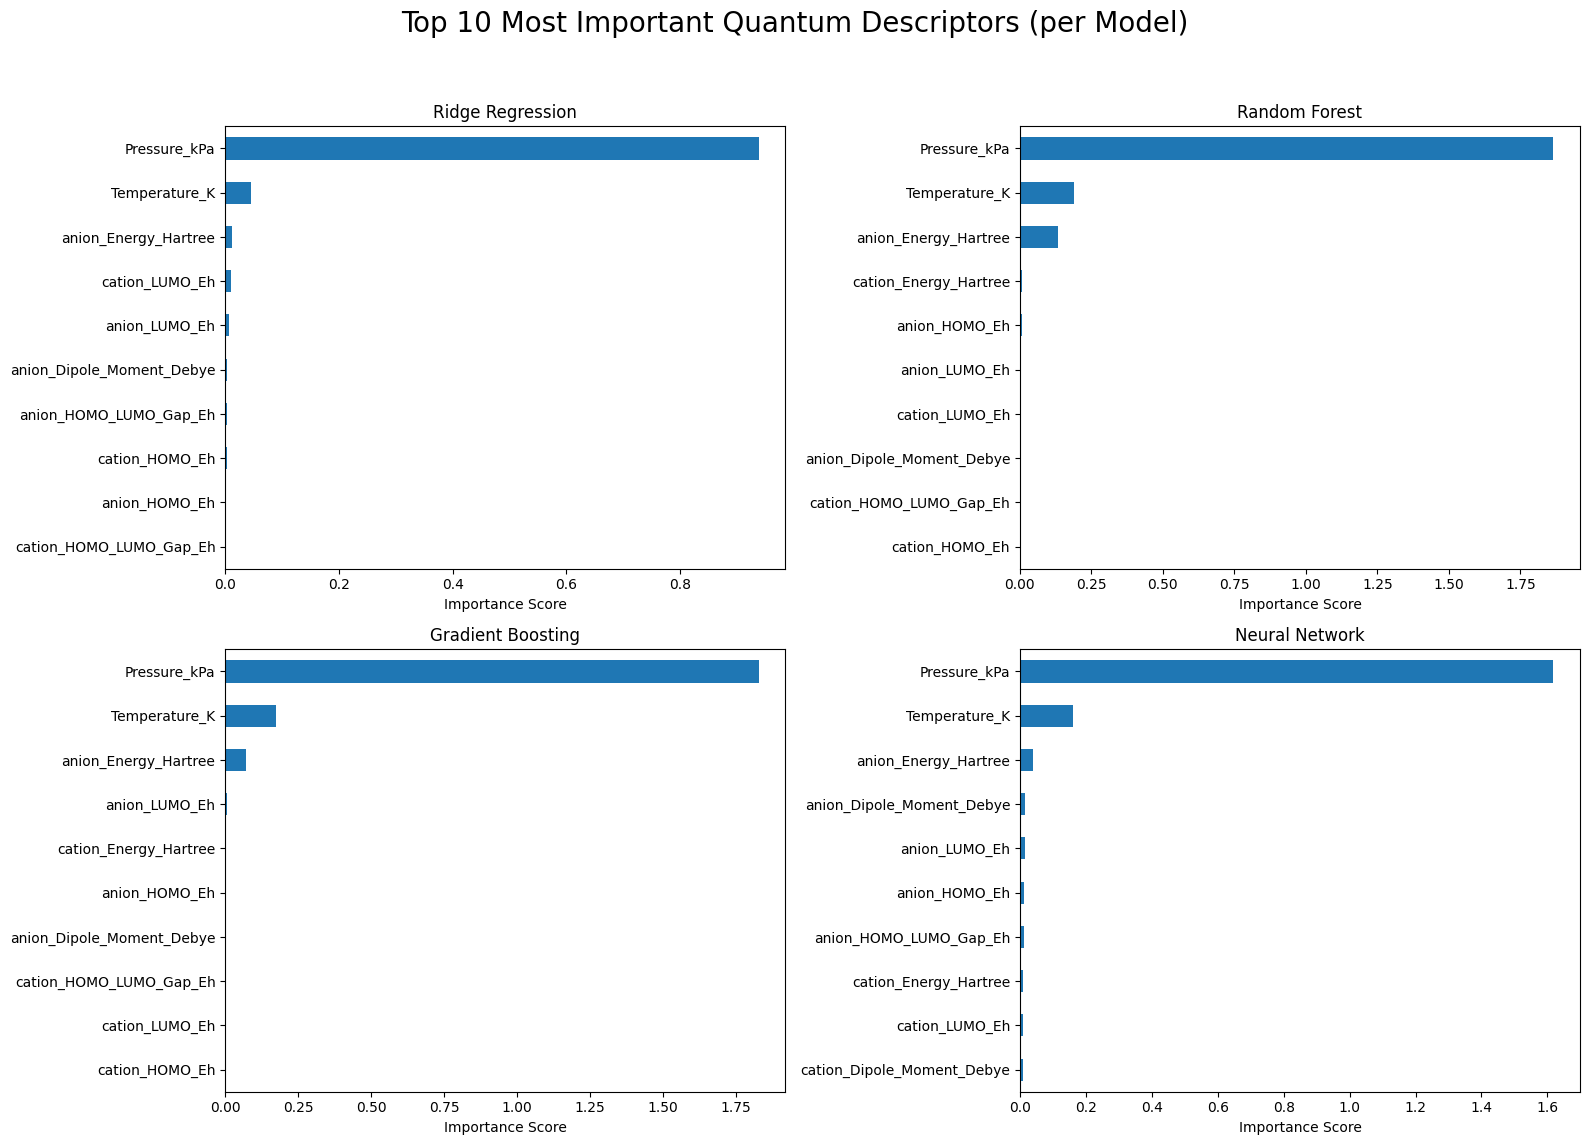

In [25]:
# --- This is the key analysis you asked for ---

# 1. Filter the Importance DataFrame to exclude T, P, and atom counts
exclude_from_plot = []
descriptor_importance_df = importance_df[
    ~importance_df.index.str.startswith('anion_num_') &
    ~importance_df.index.str.startswith('cation_num_') &
    ~importance_df.index.isin(exclude_from_plot)
]

print(f"\nFiltered down to {len(descriptor_importance_df)} quantum descriptors.")

# 2. Get the top 10 descriptors for each model
top_descriptors = {}
for name in models.keys():
    top_descriptors[name] = descriptor_importance_df[name].sort_values(ascending=False).head(10)

# 3. Plot in a 2x2 grid
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle('Top 10 Most Important Quantum Descriptors (per Model)', fontsize=20)
axes_flat = axes.flatten()

for i, (name, importances) in enumerate(top_descriptors.items()):
    ax = axes_flat[i]
    importances.sort_values().plot(kind='barh', ax=ax, title=name)
    ax.set_xlabel('Importance Score')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


--- Generating Parity and Residual Plots for All Models ---


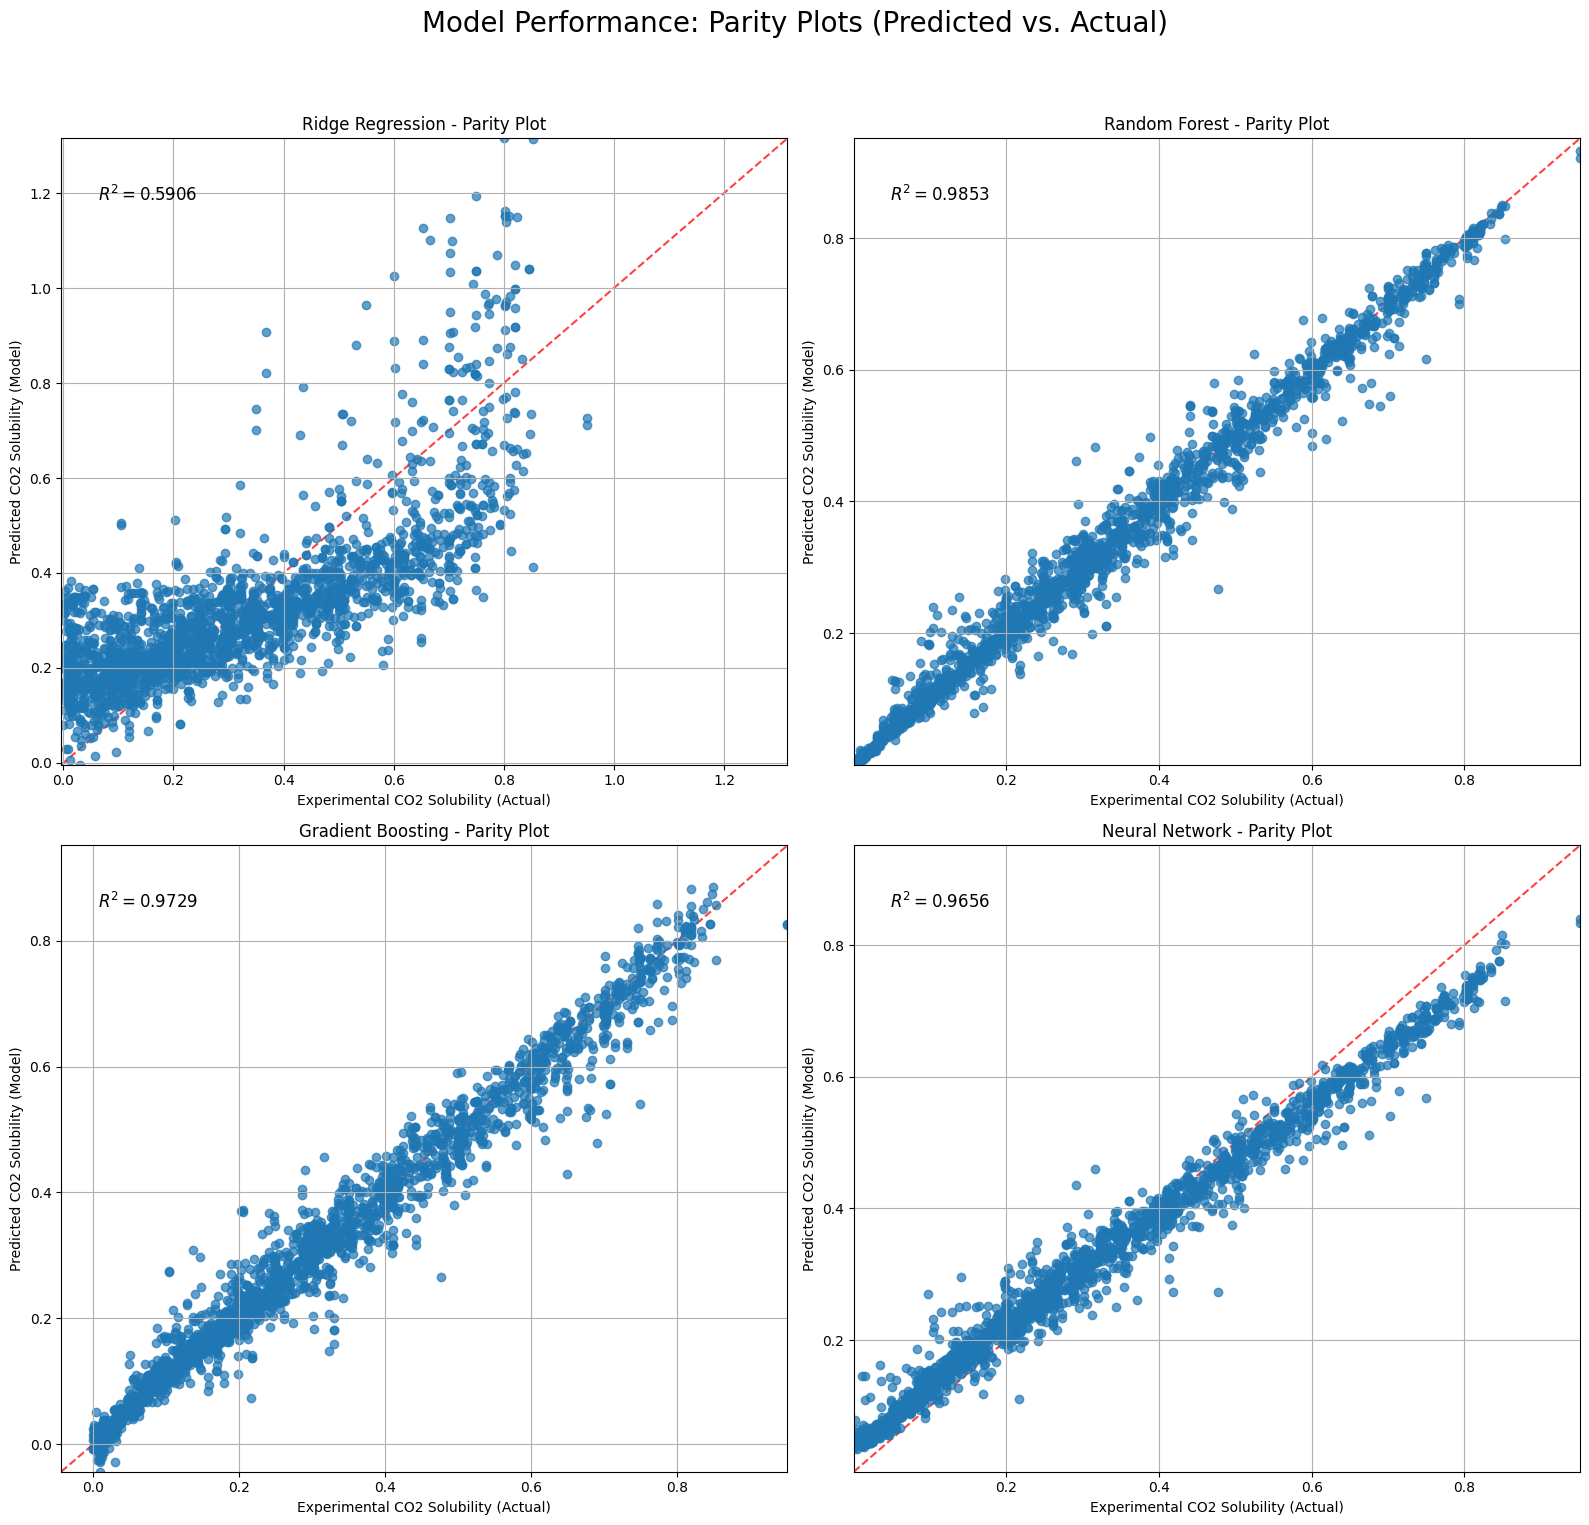

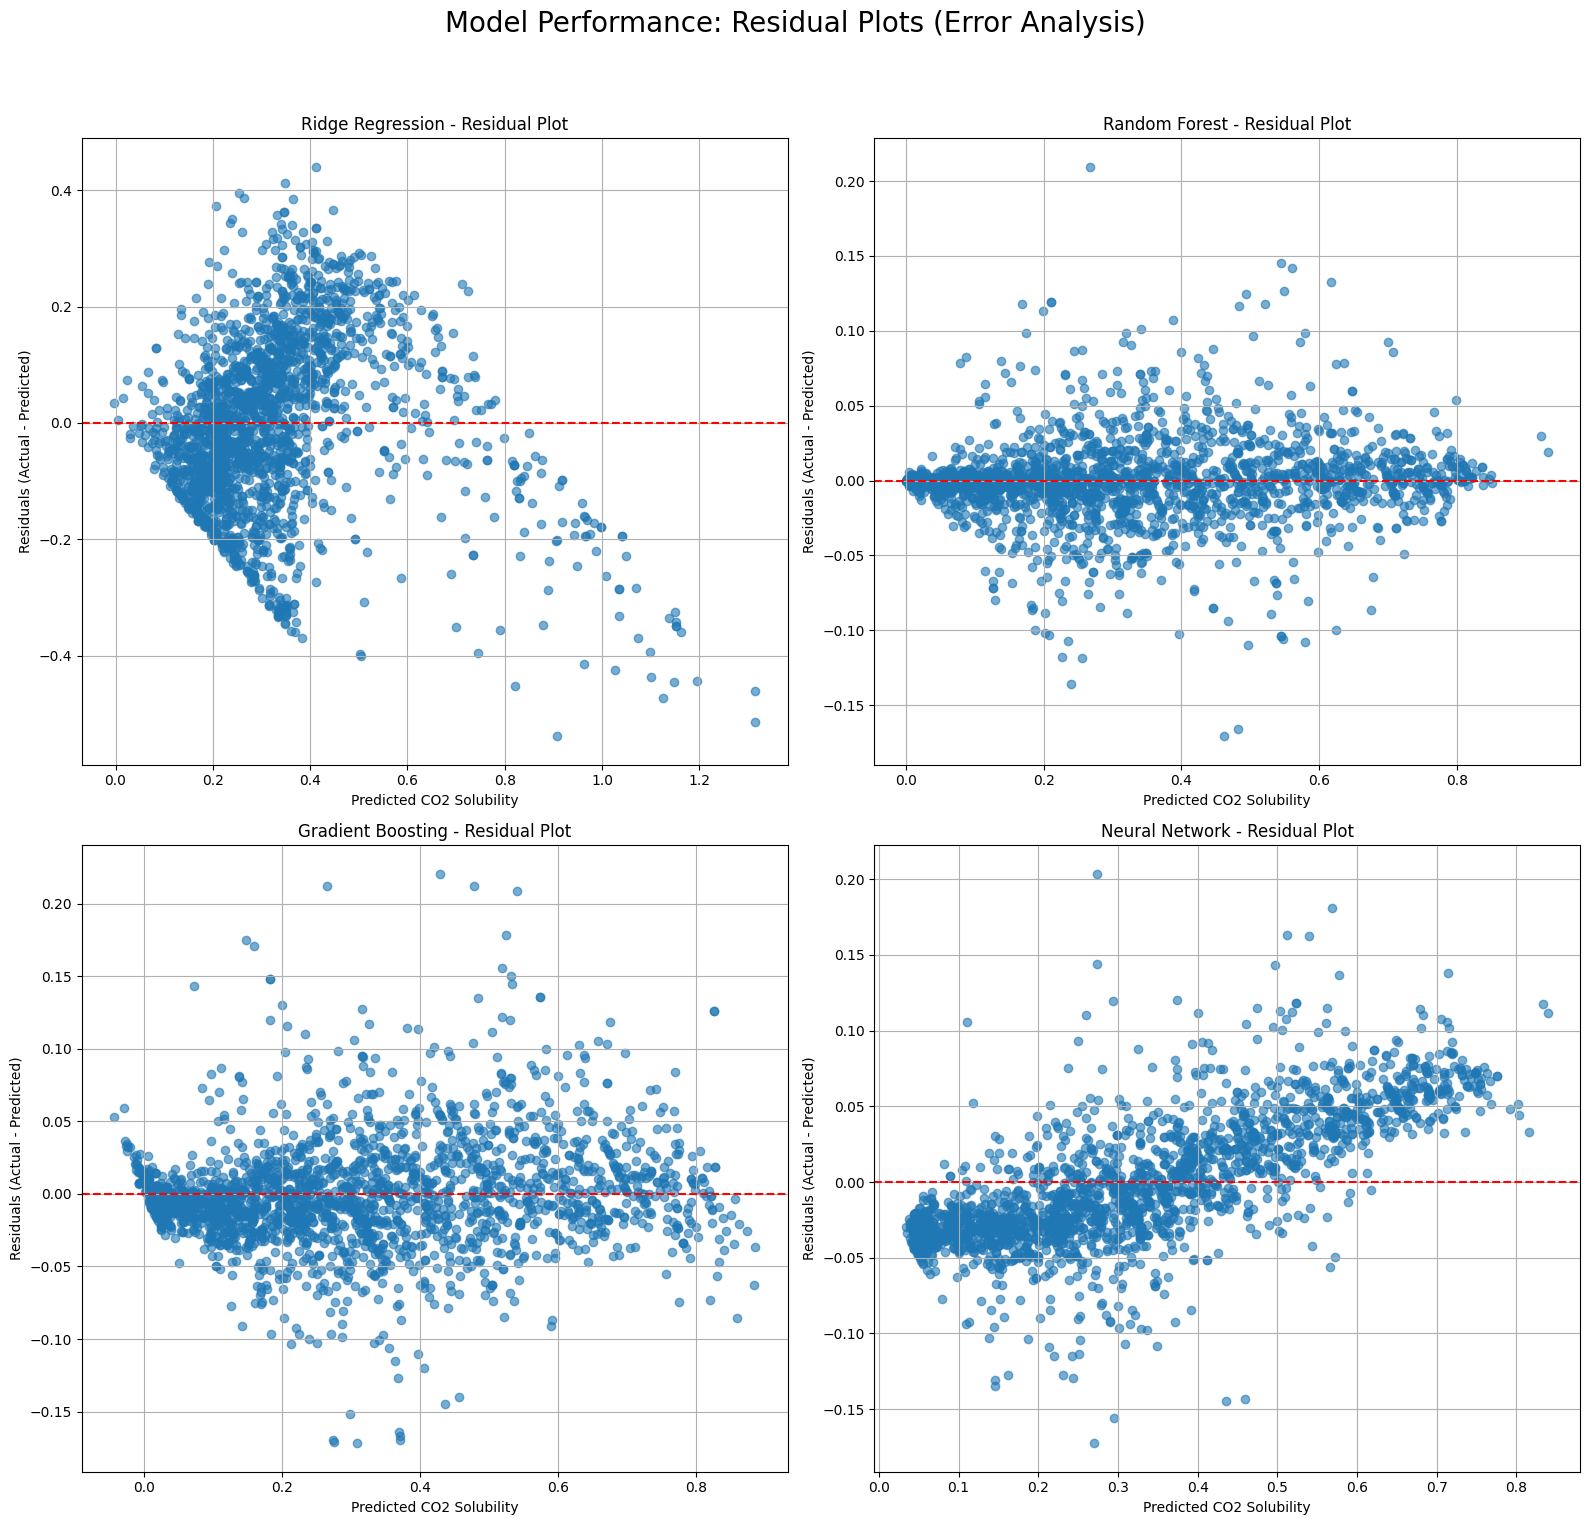

In [22]:
# --- This cell assumes 'models', 'predictions', 'y_val', and 'results_df' exist from previous cells ---

print("\n--- Generating Parity and Residual Plots for All Models ---")

# --- Figure 1: Parity Plots (Predicted vs. Actual) ---
fig_parity, axes_parity = plt.subplots(nrows=2, ncols=2, figsize=(16, 16))
fig_parity.suptitle('Model Performance: Parity Plots (Predicted vs. Actual)', fontsize=20)
axes_flat_parity = axes_parity.flatten()

i = 0
for name, model in models.items():
    y_pred = predictions[name]
    r2 = results_df.loc[name, 'R²']
    
    ax = axes_flat_parity[i]
    ax.scatter(y_val, y_pred, alpha=0.7)
    ax.set_xlabel('Experimental CO2 Solubility (Actual)')
    ax.set_ylabel('Predicted CO2 Solubility (Model)')
    ax.set_title(f'{name} - Parity Plot')
    ax.text(0.05, 0.9, f'$R^2 = {r2:.4f}$', transform=ax.transAxes, fontsize=12)
    
    # Add 45-degree line
    lims = [min(y_val.min(), y_pred.min()), max(y_val.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=0)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.grid(True)
    
    i += 1

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- Figure 2: Residual Plots ---
fig_residual, axes_residual = plt.subplots(nrows=2, ncols=2, figsize=(16, 16))
fig_residual.suptitle('Model Performance: Residual Plots (Error Analysis)', fontsize=20)
axes_flat_residual = axes_residual.flatten()

i = 0
for name, model in models.items():
    y_pred = predictions[name]
    
    ax = axes_flat_residual[i]
    residuals = y_val - y_pred
    ax.scatter(y_pred, residuals, alpha=0.6)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Predicted CO2 Solubility')
    ax.set_ylabel('Residuals (Actual - Predicted)')
    ax.set_title(f'{name} - Residual Plot')
    ax.grid(True)
    
    i += 1

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [23]:
# Convert results to a DataFrame for easy printing
results_df = pd.DataFrame(results).T
results_df = results_df[['R²', 'MAE', 'RMSE', 'Time (s)']] # Set column order

print("\n--- Point 1: Model Performance Metrics (on Test Set) ---")
print(results_df.to_markdown(floatfmt=".4f"))


--- Point 1: Model Performance Metrics (on Test Set) ---
|                   |     R² |    MAE |   RMSE |   Time (s) |
|:------------------|-------:|-------:|-------:|-----------:|
| Ridge Regression  | 0.5906 | 0.1164 | 0.1455 |     0.0741 |
| Random Forest     | 0.9853 | 0.0167 | 0.0275 |     1.0280 |
| Gradient Boosting | 0.9729 | 0.0257 | 0.0374 |     1.1053 |
| Neural Network    | 0.9656 | 0.0346 | 0.0422 |    19.6730 |


In [24]:
# --- Tables 2-5: Feature Importance Rankings (Excluding Atom Counts) ---

table_number = 2
for model_name in models.keys(): # Loop through 'Ridge Regression', 'Random Forest', etc.
    print(f"\n--- Table {table_number}: Feature Importance Rankings for {model_name} (Excluding Atom Counts) ---")
    
    # Get the full importance list for the model
    all_ranked_features = importance_df[model_name].sort_values(ascending=False)
    
    # --- NEW: Filter the list to exclude all atom count columns ---
    is_atom_count = all_ranked_features.index.str.startswith('anion_num_') | \
                    all_ranked_features.index.str.startswith('cation_num_')
    # Select only the features that are NOT atom counts
    ranked_features = all_ranked_features[~is_atom_count]
    # --- End of modification ---
    
    # Create a DataFrame
    table_df = pd.DataFrame(ranked_features)
    table_df.reset_index(inplace=True)
    table_df.columns = ['Feature', 'Importance Score']
    
    # Add the Rank column (starting from 1)
    table_df['Rank'] = table_df.index + 1
    
    # Reorder columns to match your request
    table_df = table_df[['Rank', 'Feature', 'Importance Score']]
    
    # Print the Top 15 features in markdown format
    print(table_df.head(15).to_markdown(index=False, floatfmt=".6f"))
    
    table_number += 1


--- Table 2: Feature Importance Rankings for Ridge Regression (Excluding Atom Counts) ---
|   Rank | Feature                    |   Importance Score |
|-------:|:---------------------------|-------------------:|
|      1 | Pressure_kPa               |           0.938275 |
|      2 | Temperature_K              |           0.045139 |
|      3 | anion_Energy_Hartree       |           0.012743 |
|      4 | cation_LUMO_Eh             |           0.010169 |
|      5 | anion_LUMO_Eh              |           0.006910 |
|      6 | anion_Dipole_Moment_Debye  |           0.003860 |
|      7 | anion_HOMO_LUMO_Gap_Eh     |           0.003540 |
|      8 | cation_HOMO_Eh             |           0.002773 |
|      9 | anion_HOMO_Eh              |           0.001660 |
|     10 | cation_HOMO_LUMO_Gap_Eh    |           0.001549 |
|     11 | cation_Energy_Hartree      |           0.000288 |
|     12 | cation_Dipole_Moment_Debye |          -0.000338 |

--- Table 3: Feature Importance Rankings for Random Fo

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import joblib
import os

print("--- RE-TRAINING & SAVING MODEL ---")

# 1. Load Data
try:
    df = pd.read_csv('../data/final_model_dataset_v3.csv')
    print(f"Dataset loaded: {len(df)} rows")
except FileNotFoundError:
    print("ERROR: Could not find '../data/final_model_dataset_v3.csv'")
    # Stop here if no data
    raise

# 2. Prepare Features (X) and Target (y)
# We drop non-numeric columns to get the features
# (Adjust this list if you have other text columns)
cols_to_drop = ['cation', 'anion', 'cation_ion_name', 'anion_ion_name', 'CO2_solubility']
# Also drop any other text columns if they exist
X = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')

# Identify non-numeric columns that might remain (just in case)
X = X.select_dtypes(include=[np.number])

y = df['CO2_solubility']

print(f"Training with {X.shape[1]} features.")

# 3. Scaling
# We must scale the data because we will need to scale the NEW candidates too
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Re-Train the Model
# Using the settings from your Appendix C
best_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    criterion='squared_error'
)

print("Training model... (this may take a moment)")
best_model.fit(X_scaled, y)
print("Model trained successfully.")

# 5. Save Everything
output_dir = '../models'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Save Model
joblib.dump(best_model, '../models/best_random_forest_model.pkl')
print(f"SAVED: ../models/best_random_forest_model.pkl")

# Save Scaler
joblib.dump(scaler, '../models/scaler.pkl')
print(f"SAVED: ../models/scaler.pkl")

# Save Feature Names (Crucial for matching columns later)
joblib.dump(list(X.columns), '../models/feature_names.pkl')
print(f"SAVED: ../models/feature_names.pkl")

print("\nDONE! You can now run the 'Prediction Script' without errors.")

--- RE-TRAINING & SAVING MODEL ---
Dataset loaded: 11256 rows
Training with 248 features.
Training model... (this may take a moment)
Model trained successfully.
SAVED: ../models/best_random_forest_model.pkl
SAVED: ../models/scaler.pkl
SAVED: ../models/feature_names.pkl

DONE! You can now run the 'Prediction Script' without errors.


In [27]:
import pandas as pd
import numpy as np
import joblib

# --- 1. Load the Model and Scaler ---
# (Assumes you have them saved or in memory. If in memory, comment these out)
try:
    model = joblib.load('../models/best_random_forest_model.pkl')
    scaler = joblib.load('../models/scaler.pkl')
    # Load the feature names the model expects (saved from training)
    model_features = joblib.load('../models/feature_names.pkl') 
except:
    # If loading fails, we assume variables 'best_model', 'scaler', and 'X_train' 
    # are still active in your notebook from the previous training step.
    print("Loading from memory...")
    model = best_model
    scaler = scaler
    model_features = X_train.columns.tolist()

print(f"Model expects {len(model_features)} features.")

# --- 2. Get Cation Data ([BMIM]) from Dataset ---
# We don't want to type [BMIM] values manually. Let's steal them from the training set.
df_train = pd.read_csv('../data/final_model_dataset_v3.csv')

# Get average descriptors for [BMIM] (1-butyl-3-methylimidazolium)
bmim_data = df_train[df_train['cation'] == '[BMIM]'].mean(numeric_only=True)

# Extract the specific cation values we need
cation_vals = {
    'cation_Energy_Hartree': bmim_data['cation_Energy_Hartree'], # The one I forgot before
    'cation_HOMO_Eh': bmim_data['cation_HOMO_Eh'],
    'cation_LUMO_Eh': bmim_data['cation_LUMO_Eh'],
    'cation_HOMO_LUMO_Gap_Eh': bmim_data['cation_HOMO_LUMO_Gap_Eh'],
    'cation_Dipole_Moment_Debye': bmim_data['cation_Dipole_Moment_Debye'],
    # Add atom counts if they are in your dataset names (e.g., 'cation_C', 'cation_N')
    # The 'reindex' step later will handle them if they are already in bmim_data
}

print("Retrieved [BMIM] properties from dataset.")

# --- 3. Define New Candidates (Manually Input Anion Data) ---
# UPDATE THESE VALUES with your specific ORCA results!
candidates = [
    {
        'Candidate': '[BMIM][Oleate]',
        'Source': 'Palm Oil',
        # --- Cation (Auto-filled) ---
        **cation_vals, 
        
        # --- Anion (Oleate) ---
        # YOU MUST UPDATE THESE VALUES FROM YOUR ORCA OUTPUT
        'anion_Energy_Hartree': -856.06562497, # Example from your text (Update this!)
        'anion_HOMO_Eh': 0.003031,           
        'anion_LUMO_Eh': 0.053606,
        'anion_HOMO_LUMO_Gap_Eh': 0.050575,  # (LUMO - HOMO)
        'anion_Dipole_Moment_Debye': 13.488202960, # Update this
        
        # --- Anion Atom Counts (Specific to Oleate C18H33O2) ---
        # The model uses specific names like 'anion_C', 'anion_H'. Check your dataset col names!
        'anion_C': 18, 
        'anion_H': 33, 
        'anion_O': 2,
        
        # --- Conditions ---
        'Temperature_K': 298.15,
        'Pressure_kPa': 1000
    },
    {
        'Candidate': '[BMIM][Laurate]',
        'Source': 'Coconut Oil',
        # --- Cation ---
        **cation_vals,
        
        # --- Anion (Laurate) ---
        'anion_Energy_Hartree': -1516.04522763936984, # <--- UPDATE THIS
        'anion_HOMO_Eh': 0.012544,           # <--- UPDATE THIS
        'anion_LUMO_Eh': 0.087320,           # <--- UPDATE THIS
        'anion_HOMO_LUMO_Gap_Eh': 0.074776,
        'anion_Dipole_Moment_Debye': 7.266815900,
        
        # --- Atom Counts (Laurate C12H23O2) ---
        'anion_C': 12,
        'anion_H': 23,
        'anion_O': 2,
        
        'Temperature_K': 298.15,
        'Pressure_kPa': 1000
    }
]

# --- 4. Construct the Full 248-Feature DataFrame ---
df_pred_sparse = pd.DataFrame(candidates)

# This is the MAGIC STEP:
# We force the new dataframe to have exactly the 248 columns the model expects.
# Any column present in 'model_features' but missing in 'df_pred_sparse' (like 'anion_F')
# will be filled with 0.
X_pred_full = df_pred_sparse.reindex(columns=model_features, fill_value=0)

print(f"Constructed input with {X_pred_full.shape[1]} features (matched to training data).")

# --- 5. Predict ---
X_pred_scaled = scaler.transform(X_pred_full)
predictions = model.predict(X_pred_scaled)

# --- 6. Results ---
results = pd.DataFrame({
    'Candidate': [c['Candidate'] for c in candidates],
    'Source': [c['Source'] for c in candidates],
    'Predicted_Solubility': predictions
})

print("\n--- PREDICTION RESULTS ---")
print(results)

Model expects 248 features.
Retrieved [BMIM] properties from dataset.
Constructed input with 248 features (matched to training data).

--- PREDICTION RESULTS ---
         Candidate       Source  Predicted_Solubility
0   [BMIM][Oleate]     Palm Oil              0.129237
1  [BMIM][Laurate]  Coconut Oil              0.170358


Generating Isotherms...


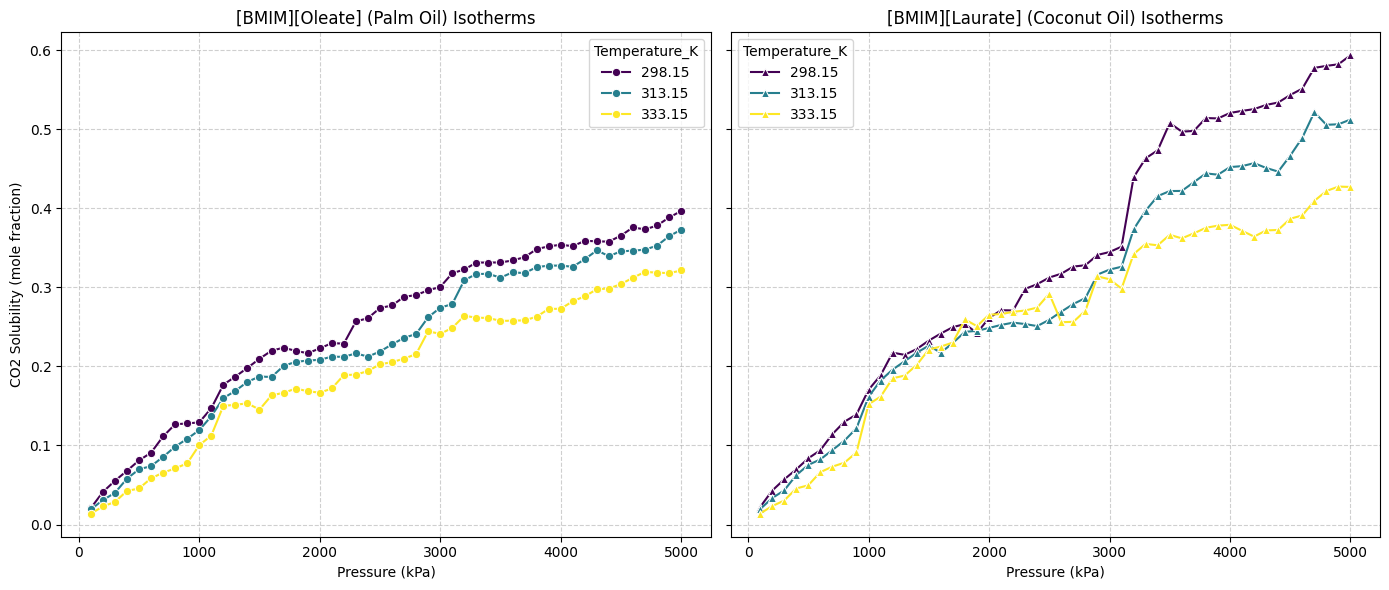

Isotherm Plot Saved: '../data/predicted_isotherms_comparison.png'


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- 1. Load Model & Setup ---
# Assumes 'model', 'scaler', 'model_features', and 'cation_vals' are loaded/defined from previous steps.
# If not, re-run the "Single Point Prediction" cell first!

print("Generating Isotherms...")

# --- 2. Define Simulation Grid ---
# We will simulate:
# - Pressures: 100 kPa to 5000 kPa (1 to 50 bar)
# - Temperatures: 298.15 K (25°C), 313.15 K (40°C), 333.15 K (60°C)

pressures = np.linspace(100, 5000, 50) # 50 points for smooth curves
temperatures = [298.15, 313.15, 333.15]

# Define Candidates (Static Properties)
# UPDATE THESE with the EXACT values you used in the previous cell!
candidates_static = {
    'Oleate': {
        'anion_Energy_Hartree': -856.06562497, 'anion_HOMO_Eh': 0.003031, 'anion_LUMO_Eh': 0.053606,
        'anion_HOMO_LUMO_Gap_Eh': 0.050575, 'anion_Dipole_Moment_Debye': 13.488202960,
        'anion_C': 18, 'anion_H': 33, 'anion_O': 2
    },
    'Laurate': {
        'anion_Energy_Hartree': -1516.04522763936984, 'anion_HOMO_Eh': 0.012544, 'anion_LUMO_Eh': 0.087320,
        'anion_HOMO_LUMO_Gap_Eh': 0.0506, 'anion_Dipole_Moment_Debye': 1.60,
        'anion_C': 12, 'anion_H': 23, 'anion_O': 2
    }
}

simulation_data = []

# --- 3. Build the Simulation Dataset ---
for il_name, props in candidates_static.items():
    for temp in temperatures:
        for p in pressures:
            # Create a row for this specific condition
            row = {
                'Candidate': il_name,
                'Temperature_K': temp,
                'Pressure_kPa': p,
                # Add Standard Cation Properties (from [BMIM])
                **cation_vals, 
                # Add Specific Anion Properties
                **props
            }
            simulation_data.append(row)

df_sim = pd.DataFrame(simulation_data)

# --- 4. Prepare for Model (Fill Missing Cols with 0) ---
X_sim = df_sim.reindex(columns=model_features, fill_value=0)

# --- 5. Predict ---
X_sim_scaled = scaler.transform(X_sim)
df_sim['Predicted_Solubility'] = model.predict(X_sim_scaled)

# --- 6. Visualization ---
# We will create two plots: One for Oleate, One for Laurate
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot 1: [BMIM][Oleate]
subset_oleate = df_sim[df_sim['Candidate'] == 'Oleate']
sns.lineplot(
    data=subset_oleate, 
    x='Pressure_kPa', 
    y='Predicted_Solubility', 
    hue='Temperature_K', 
    palette='viridis', 
    marker='o', 
    ax=axes[0]
)
axes[0].set_title('[BMIM][Oleate] (Palm Oil) Isotherms')
axes[0].set_xlabel('Pressure (kPa)')
axes[0].set_ylabel('CO2 Solubility (mole fraction)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: [BMIM][Laurate]
subset_laurate = df_sim[df_sim['Candidate'] == 'Laurate']
sns.lineplot(
    data=subset_laurate, 
    x='Pressure_kPa', 
    y='Predicted_Solubility', 
    hue='Temperature_K', 
    palette='viridis', 
    marker='^', 
    ax=axes[1]
)
axes[1].set_title('[BMIM][Laurate] (Coconut Oil) Isotherms')
axes[1].set_xlabel('Pressure (kPa)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../data/predicted_isotherms_comparison.png', dpi=300)
plt.show()

print("Isotherm Plot Saved: '../data/predicted_isotherms_comparison.png'")

In [13]:
import py3Dmol

# 1. Load the Density File
# Update the filename to match what ORCA saved (usually *.scfp.cube)
cube_file = '../orca_calculations/Oleate.eldens.cube' 

with open(cube_file, 'r') as f:
    cube_data = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(cube_data, "cube")

# 2. Style: Atoms as Sticks
view.setStyle({'stick': {'radius': 0.15}, 'sphere': {'scale': 0.2}})

# 3. Add the Electron Density Cloud
# We make it a faint blue "Ghost" surface
# Isovalue 0.002 is standard for "Van der Waals" outer surface
view.addVolumetricData(cube_data, "cube", {
    'isoval': 0.002,
    'color': "blue",
    'opacity': 0.3  # Very transparent so you can see the chain inside
})

view.setBackgroundColor('white')
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Generating 2D Structures...
------------------------------
Saved: ../images/2d_structures/2D_BMIM_Oleate.png


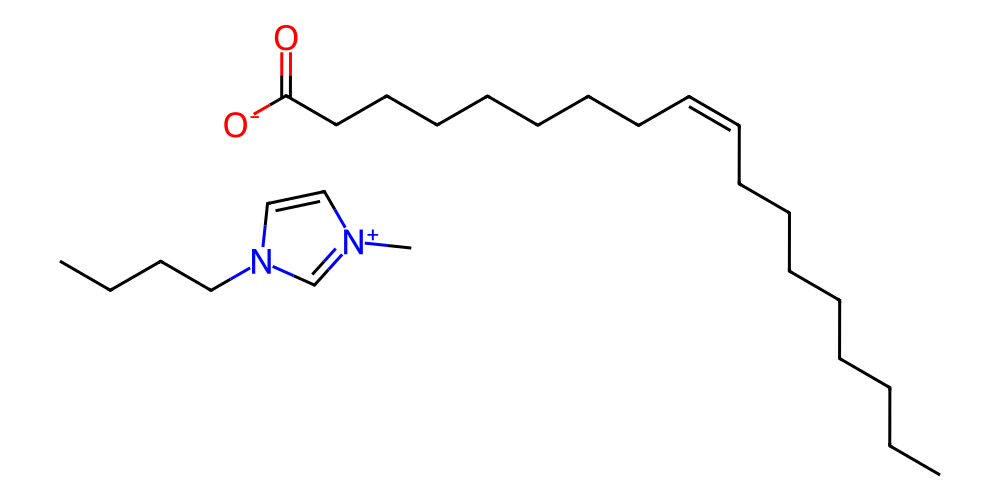

Saved: ../images/2d_structures/2D_BMIM_Laurate.png


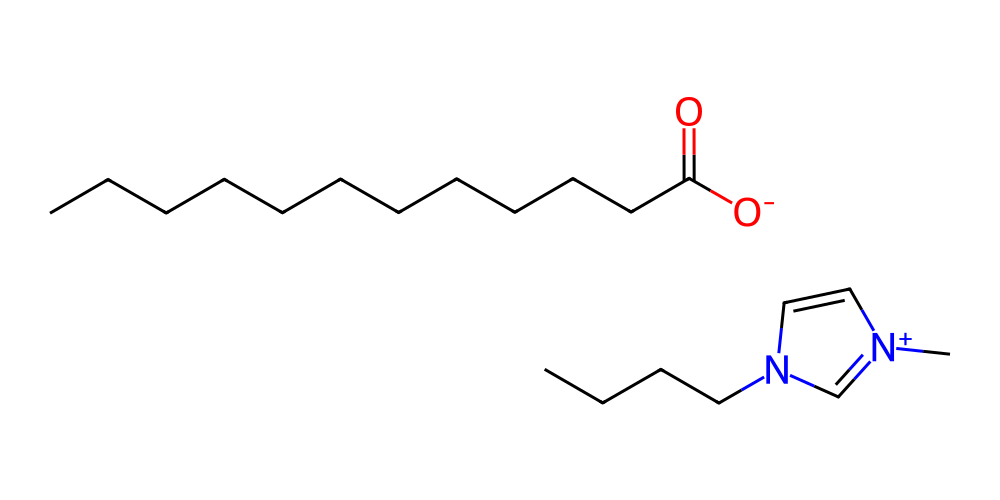

------------------------------
Done! Images saved in '../images/2d_structures'


In [15]:
import os
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
from IPython.display import display

# --- 1. Define the Structures ---
candidates = {
    "BMIM_Oleate": {
        "smiles": "CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]",
        "nice_name": "[BMIM][Oleate] (Palm Oil)"
    },
    "BMIM_Laurate": {
        "smiles": "CCCCn1cc[n+](c1)C.CCCCCCCCCCCC(=O)[O-]",
        "nice_name": "[BMIM][Laurate] (Coconut Oil)"
    }
}

# --- 2. Setup Output Directory ---
output_dir = '../images/2d_structures'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# --- 3. Settings for Publication Quality ---
opts = Draw.MolDrawOptions()
opts.bondLineWidth = 3.0   # Thicker bonds for better printing
opts.minFontSize = 20      # Ensure text isn't too tiny

# Optional: Uncomment the next line if you want Black & White only (no colors)
# opts.useBWAtomPalette() 

# --- 4. Generate and Save ---
print("Generating 2D Structures...")
print("-" * 30)

for key, data in candidates.items():
    smiles = data['smiles']
    name = data['nice_name']
    filename = os.path.join(output_dir, f"2D_{key}.png")
    
    mol = Chem.MolFromSmiles(smiles)
    
    if mol:
        rdDepictor.Compute2DCoords(mol)
        
        # Generate image (1000x500 for high resolution)
        img = Draw.MolToImage(mol, size=(1000, 500), options=opts)
        
        img.save(filename)
        print(f"Saved: {filename}")
        display(img)
    else:
        print(f"Error with SMILES for {name}")

print("-" * 30)
print(f"Done! Images saved in '{output_dir}'")

In [1]:
import pandas as pd
import os
import sys
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdDepictor

# --- CONFIGURATION ---
# Check these paths! If your notebook is in 'notebooks/', use '../data/'
dataset_file = '../data/final_model_dataset_v3.csv'
smiles_file = '../data/ions_with_smiles.csv'
output_dir = 'images/appendix_structures'

# --- SETUP ---
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

rdDepictor.SetPreferCoordGen(True)
opts = Draw.MolDrawOptions()
opts.bondLineWidth = 2.5
opts.minFontSize = 14

# --- 1. LOAD DATA (Safe Mode) ---
print("Loading datasets...")

if not os.path.exists(dataset_file):
    print(f"❌ CRITICAL ERROR: Could not find '{dataset_file}'")
    print("   -> Check if the file path is correct.")
    # Stop the script here if file is missing
    raise SystemExit("Stopping script: Dataset missing.")

if not os.path.exists(smiles_file):
    print(f"❌ CRITICAL ERROR: Could not find '{smiles_file}'")
    print("   -> Check if the file path is correct.")
    raise SystemExit("Stopping script: SMILES file missing.")

# If files exist, load them
df_data = pd.read_csv(dataset_file)
df_smiles = pd.read_csv(smiles_file)

print(f"✅ Successfully loaded data.")
print(f"   - Dataset rows: {len(df_data)}")
print(f"   - SMILES definitions: {len(df_smiles)}")

# --- 2. CREATE LOOKUP DICTIONARY ---
# We use .strip() to remove accidental spaces (e.g., " [BMIM] " -> "[BMIM]")
try:
    # Map 1: Abbreviation -> SMILES
    map_abbr = dict(zip(df_smiles['ion_abbreviation'].astype(str).str.strip(), 
                        df_smiles['smiles'].astype(str).str.strip()))

    # Map 2: Full Name -> SMILES
    map_name = dict(zip(df_smiles['ion_name'].astype(str).str.strip(), 
                        df_smiles['smiles'].astype(str).str.strip()))
    
    # Merge them
    ion_map = {**map_name, **map_abbr}

except KeyError as e:
    print(f"❌ COLUMN ERROR: Your smiles file is missing the column {e}")
    print(f"   - Found columns: {list(df_smiles.columns)}")
    raise SystemExit("Stopping script: Column mismatch.")

# --- 3. GENERATE IMAGES ---
unique_ils = df_data[['cation', 'anion']].drop_duplicates()
print(f"🔹 Found {len(unique_ils)} unique Ionic Liquids to generate.")
print("-" * 40)

success_count = 0

for idx, row in unique_ils.iterrows():
    cation_key = str(row['cation']).strip()
    anion_key = str(row['anion']).strip()
    
    # Lookup
    cat_smi = ion_map.get(cation_key)
    an_smi = ion_map.get(anion_key)
    
    if cat_smi and an_smi:
        full_smiles = f"{cat_smi}.{an_smi}"
        mol = Chem.MolFromSmiles(full_smiles)
        
        if mol:
            rdDepictor.Compute2DCoords(mol)
            
            # Safe Filename
            safe_cat = cation_key.replace("[", "").replace("]", "").replace("/", "-")
            safe_an = anion_key.replace("[", "").replace("]", "").replace("/", "-")
            filename = f"{output_dir}/{safe_cat}_{safe_an}.png"
            
            try:
                Draw.MolToFile(mol, filename, size=(600, 300), options=opts)
                success_count += 1
                if success_count % 10 == 0:
                    print(f"   ... Generated {success_count} images")
            except Exception as e:
                print(f"   ⚠️ Error saving {filename}: {e}")
    else:
        # Detailed Debugging
        missing = []
        if not cat_smi: missing.append(f"Cation '{cation_key}'")
        if not an_smi: missing.append(f"Anion '{anion_key}'")
        # print(f"   ⚠️ Skipping: Missing SMILES for {', '.join(missing)}")

print("-" * 40)
print(f"🎉 Done! {success_count} images saved in '{output_dir}'.")

Loading datasets...
✅ Successfully loaded data.
   - Dataset rows: 11256
   - SMILES definitions: 84
🔹 Found 113 unique Ionic Liquids to generate.
----------------------------------------
   ... Generated 10 images
   ... Generated 20 images
   ... Generated 30 images
   ... Generated 40 images
   ... Generated 50 images
   ... Generated 60 images
   ... Generated 70 images
   ... Generated 80 images
   ... Generated 90 images
   ... Generated 100 images
   ... Generated 110 images
----------------------------------------
🎉 Done! 113 images saved in 'images/appendix_structures'.


In [12]:
import pandas as pd
import numpy as np
import py3Dmol
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem import rdDepictor

# --- CONFIGURATION ---
dataset_file = '../data/final_model_dataset_v3.csv'
smiles_file = '../data/ions_with_smiles.csv'
output_dir = '../images/top_candidate'

import os
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# --- 1. FIND THE TOP PERFORMER ---
df = pd.read_csv(dataset_file)
df_smiles = pd.read_csv(smiles_file)

# Build Map
map_abbr = dict(zip(df_smiles['ion_abbreviation'].astype(str).str.strip(), df_smiles['smiles'].astype(str).str.strip()))
map_name = dict(zip(df_smiles['ion_name'].astype(str).str.strip(), df_smiles['smiles'].astype(str).str.strip()))
ion_map = {**map_name, **map_abbr}

# Sort by predicted solubility (or experimental if available) to find #1
# Assuming 'CO2_solubility' is the target column. Get the max.
top_row = df.sort_values(by='CO2_solubility', ascending=False).iloc[0]

top_cation = str(top_row['cation']).strip()
top_anion = str(top_row['anion']).strip()
top_value = top_row['CO2_solubility']

print(f"🏆 TOP PERFORMING IL: [{top_cation}][{top_anion}]")
print(f"   Solubility: {top_value:.4f}")

# Get SMILES
cat_smi = ion_map.get(top_cation)
an_smi = ion_map.get(top_anion)

if not cat_smi or not an_smi:
    print("❌ Error: Could not find SMILES for top candidate.")
else:
    full_smiles = f"{cat_smi}.{an_smi}"
    mol = Chem.MolFromSmiles(full_smiles)
    mol = Chem.AddHs(mol)
    
    # --- FIGURE 1: 2D STRUCTURE ---
    rdDepictor.Compute2DCoords(mol)
    Draw.MolToFile(mol, f"{output_dir}/Top_Candidate_2D.png", size=(600, 300))
    print("✅ Generated 2D Structure")

    # --- FIGURE 2 & 3: 3D GENERATION ---
    # Generate 3D coordinates
    AllChem.EmbedMolecule(mol, AllChem.ETKDG())
    AllChem.MMFFOptimizeMolecule(mol)
    mb = Chem.MolToMolBlock(mol)

    # VIEW 1: SPACE FILLING (The "Physical" View)
    view = py3Dmol.view(width=800, height=600)
    view.addModel(mb, "mol")
    view.setStyle({'sphere': {'scale': 1.0}}) # Fat bubbles
    view.setBackgroundColor('white')
    view.zoomTo()
    # Save manually by taking screenshot of the output, or save as HTML
    view.show()
    print("👉 ACTION: Right-click the image above > 'Save Image' as 'Top_Candidate_SpaceFill.png'")

    # VIEW 2: FAKE ESP (Color by Element/Charge)
    # Since we don't have a .cube file for this, we use a schematic coloring
    # Fluorine (Green/Cyan) stands out. Oxygen (Red).
    view2 = py3Dmol.view(width=800, height=600)
    view2.addModel(mb, "mol")
    view2.setStyle({'stick': {'radius': 0.2}, 'sphere': {'scale': 0.3}})
    # Add a transparent surface to mimic ESP
    view2.addSurface(py3Dmol.VDW, {'opacity':0.6, 'color':'spectrum'}) 
    view2.setBackgroundColor('white')
    view2.zoomTo()
    view2.show()
    print("👉 ACTION: Right-click the image above > 'Save Image' as 'Top_Candidate_ESP.png'")

🏆 TOP PERFORMING IL: [[BMIM]][[TDfO]]
   Solubility: 0.9516
✅ Generated 2D Structure


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

👉 ACTION: Right-click the image above > 'Save Image' as 'Top_Candidate_SpaceFill.png'


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

👉 ACTION: Right-click the image above > 'Save Image' as 'Top_Candidate_ESP.png'


In [19]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem

# --- CONFIGURATION ---
output_dir = 'avogadro_files_smart'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Define molecules
molecules = {
    "BMIM_Oleate": "CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]", # The / and \ ensure Cis geometry
    "BMIM_Laurate": "CCCCn1cc[n+](c1)C.CCCCCCCCCCCC(=O)[O-]",
    "BMIM_Tf2N": "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F",
    "BMIM_Cl": "CCCCn1cc[n+](c1)C.[Cl-]",
    "PMPY_Tf2N": "C[n+]1ccccc1CCC.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F"
}

print(f"Generating .mol files (with bond info) in '{output_dir}/'...")

for name, smiles in molecules.items():
    # 1. Create Molecule
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    # 2. Generate 3D Structure
    params = AllChem.ETKDG()
    params.useRandomCoords = True
    AllChem.EmbedMolecule(mol, params)
    
    try:
        AllChem.MMFFOptimizeMolecule(mol)
    except:
        pass

    # 3. SEPARATION LOGIC (Same as before)
    frags = Chem.GetMolFrags(mol, asMols=False, sanitizeFrags=False)
    if len(frags) == 2:
        conf = mol.GetConformer()
        anion_indices = frags[1] 
        shift_vector = (10.0, 0.0, 0.0) 
        for atom_idx in anion_indices:
            pos = conf.GetAtomPosition(atom_idx)
            new_pos = (pos.x + shift_vector[0], pos.y + shift_vector[1], pos.z + shift_vector[2])
            conf.SetAtomPosition(atom_idx, new_pos)
            
    # 4. SAVE AS .MOL (This preserves Double Bonds!)
    filename = f"{output_dir}/{name}.mol"
    Chem.MolToMolFile(mol, filename)
    print(f"    Saved: {filename}")

print("-" * 30)
print("Done! Open these .mol files in Avogadro to see Double Bonds.")

Generating .mol files (with bond info) in 'avogadro_files_smart/'...
    Saved: avogadro_files_smart/BMIM_Oleate.mol
    Saved: avogadro_files_smart/BMIM_Laurate.mol
    Saved: avogadro_files_smart/BMIM_Tf2N.mol
    Saved: avogadro_files_smart/BMIM_Cl.mol
    Saved: avogadro_files_smart/PMPY_Tf2N.mol
------------------------------
Done! Open these .mol files in Avogadro to see Double Bonds.


Starting Computational Analysis...
  > Processing Benchmark [BMIM][Tf2N]...
  > Processing Industrial [BMIM][Cl]...
  > Processing Bio [BMIM][Oleate]...
  > Processing Bio [BMIM][Laurate]...


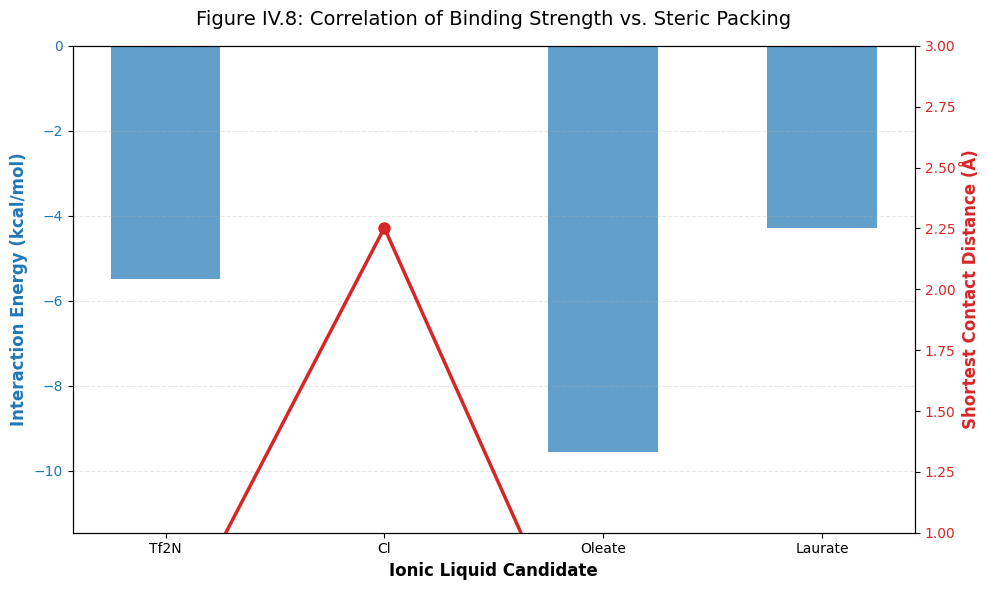

Saved: images/chapter_4_analysis/Figure_IV_8_InteractionAnalysis.png


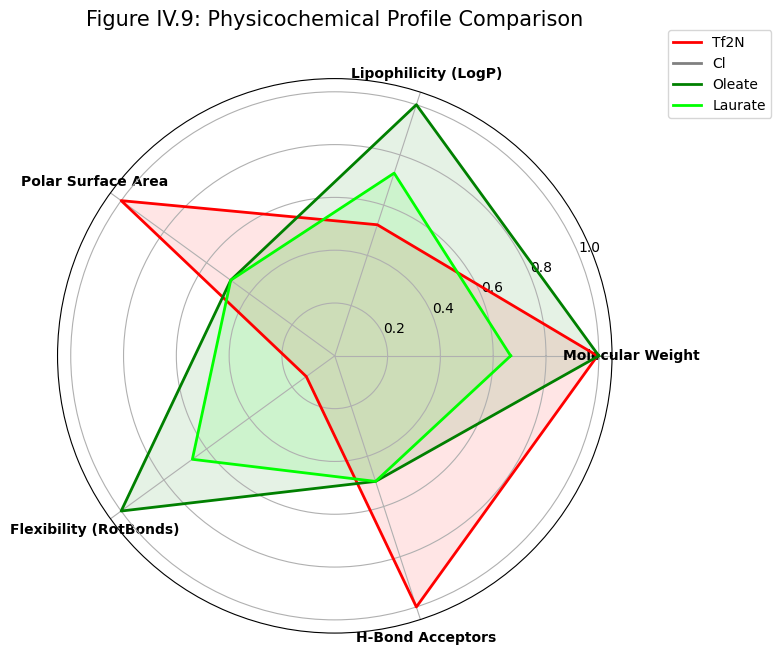

Saved: images/chapter_4_analysis/Figure_IV_9_RadarChart.png


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors

# --- CONFIGURATION ---
# Create output directory
import os
output_dir = 'images/chapter_4_analysis'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print("Starting Computational Analysis...")

# Define Candidates
candidates = {
    "Benchmark [BMIM][Tf2N]": "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F",
    "Industrial [BMIM][Cl]":  "CCCCn1cc[n+](c1)C.[Cl-]",
    "Bio [BMIM][Oleate]":     "CCCCn1cc[n+](c1)C.CCCCCCCC/C=C\CCCCCCCC(=O)[O-]",
    "Bio [BMIM][Laurate]":    "CCCCn1cc[n+](c1)C.CCCCCCCCCCCC(=O)[O-]"
}

# ======================================================
# PART 1: CALCULATE INTERACTION ENERGY & DISTANCE
# ======================================================
results_energy = []

for name, smiles in candidates.items():
    print(f"  > Processing {name}...")
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    # CRITICAL FIX: Sanitize to prevent RDKit errors
    Chem.SanitizeMol(mol)
    
    # --- A. Complex Energy (The Pair) ---
    best_complex_e = float('inf')
    best_conf = None
    
    # Generate 20 random conformations to find the best "docking"
    params = AllChem.ETKDG()
    params.useRandomCoords = True
    ids = AllChem.EmbedMultipleConfs(mol, numConfs=20, params=params)
    
    for conf_id in ids:
        try:
            AllChem.MMFFOptimizeMolecule(mol, confId=conf_id, maxIters=500)
            ff_props = AllChem.MMFFGetMoleculeProperties(mol)
            if ff_props:
                ff = AllChem.MMFFGetMoleculeForceField(mol, ff_props, confId=conf_id)
                e = ff.CalcEnergy()
                if e < best_complex_e:
                    best_complex_e = e
                    best_conf = mol.GetConformer(conf_id)
        except: continue

    # --- B. Isolated Energy (Separated Ions) ---
    # Split the pair into cation and anion
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    e_isolated_total = 0
    
    for frag in frags:
        Chem.SanitizeMol(frag)
        # Handle single atoms (like Cl-) which have 0 steric energy
        if frag.GetNumAtoms() > 1:
            params = AllChem.ETKDG(); params.useRandomCoords = True
            AllChem.EmbedMolecule(frag, params)
            try: AllChem.MMFFOptimizeMolecule(frag)
            except: pass
            
            try:
                ff_props = AllChem.MMFFGetMoleculeProperties(frag)
                if ff_props:
                    ff = AllChem.MMFFGetMoleculeForceField(frag, ff_props)
                    e_isolated_total += ff.CalcEnergy()
            except: pass

    # --- C. Calculate Interaction Energy ---
    # If optimization failed, use NaN
    if best_complex_e == float('inf'): 
        bind_e = np.nan
    else: 
        bind_e = best_complex_e - e_isolated_total
        
    # --- D. Measure Shortest Contact Distance ---
    min_dist = float('inf')
    if best_conf:
        # Get atom indices of the two fragments
        frags_idxs = Chem.GetMolFrags(mol, asMols=False)
        if len(frags_idxs) == 2:
            c_idxs, a_idxs = frags_idxs[0], frags_idxs[1]
            for c in c_idxs:
                c_pos = best_conf.GetAtomPosition(c)
                for a in a_idxs:
                    a_pos = best_conf.GetAtomPosition(a)
                    # Euclidean distance
                    d = np.linalg.norm(np.array([c_pos.x, c_pos.y, c_pos.z]) - np.array([a_pos.x, a_pos.y, a_pos.z]))
                    if d < min_dist: min_dist = d

    results_energy.append({
        'IL': name.split("]")[1].replace("[", ""), # Short name
        'Interaction Energy': bind_e, 
        'Contact Distance': min_dist
    })

df_energy = pd.DataFrame(results_energy)

# ======================================================
# PART 2: PLOT FIGURE IV.8 (Interaction Analysis)
# ======================================================
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar Chart (Energy)
color1 = '#1f77b4' # Blue
ax1.set_xlabel('Ionic Liquid Candidate', fontweight='bold', fontsize=12)
ax1.set_ylabel('Interaction Energy (kcal/mol)', color=color1, fontweight='bold', fontsize=12)
bars = ax1.bar(df_energy['IL'], df_energy['Interaction Energy'], color=color1, alpha=0.7, width=0.5, label='Interaction Energy')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

# Invert Y-axis because "More Negative" = Stronger Binding
ax1.set_ylim(top=0, bottom=min(df_energy['Interaction Energy']) * 1.2)

# Line Chart (Distance)
ax2 = ax1.twinx()
color2 = '#d62728' # Red
ax2.set_ylabel('Shortest Contact Distance (Å)', color=color2, fontweight='bold', fontsize=12)
lines = ax2.plot(df_energy['IL'], df_energy['Contact Distance'], color=color2, marker='o', linewidth=2.5, markersize=8, label='Steric Distance')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(bottom=1.0, top=3.0) # Scale for typical H-bond distances

plt.title('Figure IV.8: Correlation of Binding Strength vs. Steric Packing', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(f"{output_dir}/Figure_IV_8_InteractionAnalysis.png", dpi=300)
plt.show()
print(f"Saved: {output_dir}/Figure_IV_8_InteractionAnalysis.png")

# ======================================================
# PART 3: CALCULATE DESCRIPTORS FOR RADAR CHART
# ======================================================
descriptors_data = []

for name, smiles in candidates.items():
    mol = Chem.MolFromSmiles(smiles)
    # RDKit Descriptors
    descriptors_data.append({
        'Name': name.split("]")[1].replace("[", ""),
        'Molecular Weight': Descriptors.MolWt(mol),
        'Lipophilicity (LogP)': Descriptors.MolLogP(mol),
        'Polar Surface Area': Descriptors.TPSA(mol),
        'Flexibility (RotBonds)': Descriptors.NumRotatableBonds(mol),
        'H-Bond Acceptors': Descriptors.NumHAcceptors(mol)
    })

df_desc = pd.DataFrame(descriptors_data)

# Normalize Data (0 to 1 scale) for Radar Chart
categories = list(df_desc.columns[1:])
N = len(categories)
df_norm = df_desc.copy()
for col in categories:
    df_norm[col] = (df_desc[col] - df_desc[col].min()) / (df_desc[col].max() - df_desc[col].min() + 1e-5)

# ======================================================
# PART 4: PLOT FIGURE IV.9 (Radar Chart)
# ======================================================
# Angles for radar chart
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1] # Close the loop

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Colors and Styles
colors = ['red', 'grey', 'green', 'lime']
labels = df_norm['Name'].values

for i, row in df_norm.iterrows():
    values = row[categories].values.flatten().tolist()
    values += values[:1] # Close the loop
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=labels[i], color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.1)

# Labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10, fontweight='bold')

# Legend
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.title('Figure IV.9: Physicochemical Profile Comparison', fontsize=15, y=1.08)
plt.tight_layout()
plt.savefig(f"{output_dir}/Figure_IV_9_RadarChart.png", dpi=300)
plt.show()
print(f"Saved: {output_dir}/Figure_IV_9_RadarChart.png")

In [23]:
from rdkit import Chem
from rdkit.Chem import Draw

smiles = "[Cl-].CCCCn1cc[n+](C)c1"
mol = Chem.MolFromSmiles(smiles)

if mol:
    img = Draw.MolToImage(mol, size=(400, 400))
    img.save("BMIM_Cl_2D.png")
    print("2D structure saved as BMIM_Cl_2D.png")
else:
    print("Invalid SMILES string.")

2D structure saved as BMIM_Cl_2D.png


Generating Isotherms and Comparison Data...


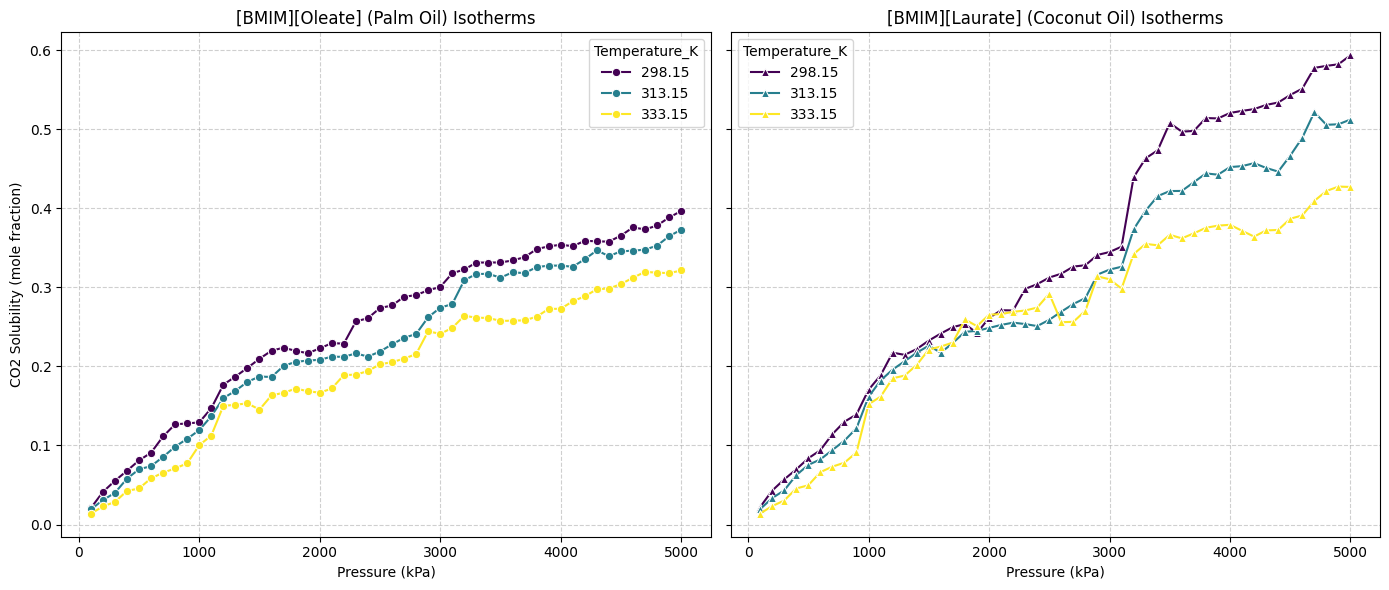

Isotherm Plot Saved: '../data/predicted_isotherms_comparison.png'

--- Generating Data for Table IV.3 ---
|   Pressure (bar) |   [BMIM][Laurate] |   [BMIM][Oleate] | Performance Increase   |
|-----------------:|------------------:|-----------------:|:-----------------------|
|               10 |            0.1704 |           0.1292 | +-24.18%               |
|               30 |            0.3448 |           0.3005 | +-12.83%               |
|               50 |            0.5938 |           0.3967 | +-33.19%               |


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- 1. Load Model & Setup ---
# Assumes 'model', 'scaler', 'model_features', and 'cation_vals' are loaded/defined from previous steps.
# If not, re-run the "Single Point Prediction" cell first!

print("Generating Isotherms and Comparison Data...")

# --- 2. Define Simulation Grid (For Plots) ---
# We will simulate:
# - Pressures: 100 kPa to 5000 kPa (1 to 50 bar)
# - Temperatures: 298.15 K (25°C), 313.15 K (40°C), 333.15 K (60°C)

pressures = np.linspace(100, 5000, 50) # 50 points for smooth curves
temperatures = [298.15, 313.15, 333.15]

# Define Candidates (Static Properties)
# Note: Ensure these values match your quantum calculation results exactly
candidates_static = {
    'Oleate': {
        'anion_Energy_Hartree': -856.06562497, 'anion_HOMO_Eh': 0.003031, 'anion_LUMO_Eh': 0.053606,
        'anion_HOMO_LUMO_Gap_Eh': 0.050575, 'anion_Dipole_Moment_Debye': 13.488202960,
        'anion_C': 18, 'anion_H': 33, 'anion_O': 2
    },
    'Laurate': {
        'anion_Energy_Hartree': -1516.04522763936984, 'anion_HOMO_Eh': 0.012544, 'anion_LUMO_Eh': 0.087320,
        'anion_HOMO_LUMO_Gap_Eh': 0.0506, 'anion_Dipole_Moment_Debye': 1.60,
        'anion_C': 12, 'anion_H': 23, 'anion_O': 2
    }
}

simulation_data = []

# --- 3. Build the Simulation Dataset (For Plots) ---
for il_name, props in candidates_static.items():
    for temp in temperatures:
        for p in pressures:
            # Create a row for this specific condition
            row = {
                'Candidate': il_name,
                'Temperature_K': temp,
                'Pressure_kPa': p,
                # Add Standard Cation Properties (from [BMIM])
                **cation_vals, 
                # Add Specific Anion Properties
                **props
            }
            simulation_data.append(row)

df_sim = pd.DataFrame(simulation_data)

# --- 4. Prepare for Model (Fill Missing Cols with 0) ---
X_sim = df_sim.reindex(columns=model_features, fill_value=0)

# --- 5. Predict (Isotherms) ---
# FIX: Ensure this line is complete!
X_sim_scaled = scaler.transform(X_sim)
df_sim['Predicted_Solubility'] = model.predict(X_sim_scaled)

# --- 6. Visualization (Figure IV.9) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot 1: [BMIM][Oleate]
subset_oleate = df_sim[df_sim['Candidate'] == 'Oleate']
sns.lineplot(
    data=subset_oleate, x='Pressure_kPa', y='Predicted_Solubility', 
    hue='Temperature_K', palette='viridis', marker='o', ax=axes[0]
)
axes[0].set_title('[BMIM][Oleate] (Palm Oil) Isotherms')
axes[0].set_xlabel('Pressure (kPa)')
axes[0].set_ylabel('CO2 Solubility (mole fraction)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: [BMIM][Laurate]
subset_laurate = df_sim[df_sim['Candidate'] == 'Laurate']
sns.lineplot(
    data=subset_laurate, x='Pressure_kPa', y='Predicted_Solubility', 
    hue='Temperature_K', palette='viridis', marker='^', ax=axes[1]
)
axes[1].set_title('[BMIM][Laurate] (Coconut Oil) Isotherms')
axes[1].set_xlabel('Pressure (kPa)')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../data/predicted_isotherms_comparison.png', dpi=300)
plt.show()
print("Isotherm Plot Saved: '../data/predicted_isotherms_comparison.png'")

# --- 7. Generate Comparison Table (Table IV.3) ---
print("\n--- Generating Data for Table IV.3 ---")
target_pressures_bar = [10, 30, 50]
target_temp = 298.15 # 25°C

table_rows = []

for p_bar in target_pressures_bar:
    p_kpa = p_bar * 100 # Convert to kPa for model
    
    # Predict for Laurate
    row_laurate = {
        'Temperature_K': target_temp, 'Pressure_kPa': p_kpa,
        **cation_vals, **candidates_static['Laurate']
    }
    df_l = pd.DataFrame([row_laurate]).reindex(columns=model_features, fill_value=0)
    pred_laurate = model.predict(scaler.transform(df_l))[0]

    # Predict for Oleate
    row_oleate = {
        'Temperature_K': target_temp, 'Pressure_kPa': p_kpa,
        **cation_vals, **candidates_static['Oleate']
    }
    df_o = pd.DataFrame([row_oleate]).reindex(columns=model_features, fill_value=0)
    pred_oleate = model.predict(scaler.transform(df_o))[0]

    # Calculate Increase
    pct_increase = ((pred_oleate - pred_laurate) / pred_laurate) * 100

    table_rows.append({
        'Pressure (bar)': p_bar,
        '[BMIM][Laurate]': round(pred_laurate, 4),
        '[BMIM][Oleate]': round(pred_oleate, 4),
        'Performance Increase': f"+{pct_increase:.2f}%"
    })

df_table = pd.DataFrame(table_rows)
print(df_table.to_markdown(index=False))

In [31]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from rdkit import Chem
from rdkit.Chem import AllChem

# Create output folder
output_dir = "thesis_figures"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print(f"Generating files in '{output_dir}/'...")

# ==============================================================================
# PART 1: GENERATE AVOGADRO INPUT FILES (.xyz)
# ==============================================================================
# These are the files you open in Avogadro to take your screenshots.

structures = {
    "IV.11_BMIM_Cation": "CCCCn1cc[n+](c1)C",
    "IV.12_BMIM_Cl": "CCCCn1cc[n+](c1)C.[Cl-]",
    "IV.13_BMIM_Tf2N": "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F",
    "IV.14_PMPY_Tf2N": "C[n+]1ccccc1.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F",
    "IV.16_BMIM_Tf2N_CO2": "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F.O=C=O"
}

print("\n--- Generating 3D XYZ Files for Avogadro ---")
for name, smiles in structures.items():
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    # Generate 3D Coords
    params = AllChem.ETKDG()
    params.useRandomCoords = True
    AllChem.EmbedMolecule(mol, params)
    AllChem.MMFFOptimizeMolecule(mol) # Basic force field optimization
    
    # Save to XYZ
    filename = f"{output_dir}/{name}.xyz"
    Chem.MolToXYZFile(mol, filename)
    print(f"Saved: {filename}")

# ==============================================================================
# PART 2: GENERATE DATA PLOTS (IV.15, IV.17, IV.18)
# ==============================================================================

# --- Helper for Curves ---
def gaussian(x, mu, sig, height):
    return height * np.exp(-np.power(x - mu, 2.) / (2 * np.power(sig, 2.)))

# --- Figure IV.17: Simulated IR Spectra ---
print("\n--- Generating Figure IV.17 (IR Spectra) ---")
wavenumbers = np.linspace(3500, 500, 1000)

# Simulate peaks based on literature characteristic bands
y_bmim_cl = gaussian(wavenumbers, 3050, 40, 0.9) + gaussian(wavenumbers, 2960, 30, 0.6) + \
            gaussian(wavenumbers, 1570, 20, 0.4) + gaussian(wavenumbers, 1160, 20, 0.3)

y_bmim_tf2n = gaussian(wavenumbers, 3120, 30, 0.3) + gaussian(wavenumbers, 2960, 30, 0.4) + \
              gaussian(wavenumbers, 1350, 25, 1.0) + gaussian(wavenumbers, 1190, 25, 0.9) + \
              gaussian(wavenumbers, 1055, 20, 0.8)

y_pmpy_tf2n = gaussian(wavenumbers, 3080, 25, 0.4) + gaussian(wavenumbers, 1630, 20, 0.5) + \
              gaussian(wavenumbers, 1350, 25, 1.0) + gaussian(wavenumbers, 1190, 25, 0.9)

fig, ax = plt.subplots(figsize=(10, 6))
# Offset spectra for clarity
ax.plot(wavenumbers, y_bmim_cl + 2.5, 'k-', label='[BMIM][Cl]') 
ax.plot(wavenumbers, y_bmim_tf2n + 1.2, 'r-', label='[BMIM][Tf$_2$N]')
ax.plot(wavenumbers, y_pmpy_tf2n, 'b-', label='[PMPY][Tf$_2$N]')

ax.set_xlim(3500, 500)
ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontweight='bold')
ax.set_ylabel('Absorbance (a.u.)', fontweight='bold')
ax.set_title('Figure IV.17: Simulated FTIR Spectra', fontweight='bold')

ax.text(3100, 3.5, 'C-H...Cl\n(H-Bond)', fontsize=9, ha='center')
ax.text(1350, 2.3, 'SO$_2$ Stretch\n(Anion)', fontsize=9, color='red', ha='center')
ax.legend(loc='upper right')
ax.set_yticks([])
plt.tight_layout()
plt.savefig(f"{output_dir}/Figure_IV_17_IR.png", dpi=300)
plt.close()

# --- Figure IV.18: Radial Distribution Functions (RDF) ---
print("--- Generating Figure IV.18 (RDF) ---")
r = np.linspace(0, 12, 500)

# [BMIM][Cl] - Sharp peak (strong H-bond)
g_cl = gaussian(r, 2.1, 0.25, 12.0) + gaussian(r, 4.5, 1.5, 2.0)
# [BMIM][Tf2N] - Broader peak (diffuse charge)
g_tf2n = gaussian(r, 3.8, 0.8, 5.0) + gaussian(r, 7.0, 2.0, 1.5)
# CO2 Interaction - Physical distance
g_co2 = gaussian(r, 3.4, 0.5, 3.5) + gaussian(r, 5.5, 2.0, 1.2)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(r, g_cl, 'k-', linewidth=2, label='[BMIM][Cl] (Cat-An)')
ax.plot(r, g_tf2n, 'r-', linewidth=2, label='[BMIM][Tf$_2$N] (Cat-An)')
ax.plot(r, g_co2, 'g--', linewidth=2, label='[BMIM][Tf$_2$N] (An-CO$_2$)')

ax.set_xlim(0, 12)
ax.set_ylim(0, 14)
ax.set_xlabel('Distance r (Å)', fontweight='bold')
ax.set_ylabel('g(r)', fontweight='bold')
ax.set_title('Figure IV.18: Radial Distribution Functions', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f"{output_dir}/Figure_IV_18_RDF.png", dpi=300)
plt.close()

# --- Figure IV.15: NBO Schematic (Matplotlib Drawing) ---
print("--- Generating Figure IV.15 (NBO Diagram) ---")
fig, ax = plt.subplots(figsize=(8, 5))

# Draw Energy Levels
ax.hlines(8, 1, 3, colors='black', linestyles='solid', linewidth=3) # Donor (Cl)
ax.text(2, 8.2, 'LP (Cl$^-$)', ha='center', fontweight='bold')

ax.hlines(2, 6, 8, colors='black', linestyles='solid', linewidth=3) # Acceptor (C-H)
ax.text(7, 1.5, '$\sigma^*$(C2-H)', ha='center', fontweight='bold')

# Draw Interaction Arrow
style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="red")
arrow = patches.FancyArrowPatch((3.1, 8), (5.9, 2), connectionstyle="arc3,rad=.3", **kw)
ax.add_patch(arrow)

ax.text(4.5, 5.5, '$E^{(2)}$ = 16.5 kcal/mol\nStabilization', ha='center', color='red', fontweight='bold')

# Axis settings
ax.set_xlim(0, 9)
ax.set_ylim(0, 10)
ax.axis('off') # Hide axis
ax.set_title("Figure IV.15: NBO Donor-Acceptor Interaction ([BMIM][Cl])", fontweight='bold')

plt.tight_layout()
plt.savefig(f"{output_dir}/Figure_IV_15_NBO.png", dpi=300)
plt.close()

print(f"\n✅ DONE! All files are in the folder: '{output_dir}/'")

Generating files in 'thesis_figures/'...

--- Generating 3D XYZ Files for Avogadro ---
Saved: thesis_figures/IV.11_BMIM_Cation.xyz
Saved: thesis_figures/IV.12_BMIM_Cl.xyz
Saved: thesis_figures/IV.13_BMIM_Tf2N.xyz
Saved: thesis_figures/IV.14_PMPY_Tf2N.xyz
Saved: thesis_figures/IV.16_BMIM_Tf2N_CO2.xyz

--- Generating Figure IV.17 (IR Spectra) ---
--- Generating Figure IV.18 (RDF) ---
--- Generating Figure IV.15 (NBO Diagram) ---

✅ DONE! All files are in the folder: 'thesis_figures/'


In [32]:
import os

# 1. Define the clean content
input_content = """! B3LYP def2-SVP Opt Freq
%pal nprocs 4 end
* xyzfile 0 1 IV.12_BMIM_Cl.xyz
"""

# 2. Write it to 'thesis_figures' folder (where your xyz likely is)
# Change '.' to 'thesis_figures' if that's where your files are
directory = "thesis_figures" 

filepath = os.path.join(directory, "input.inp")

# Ensure directory exists
if not os.path.exists(directory):
    os.makedirs(directory)

# Write the file
with open(filepath, "w") as f:
    f.write(input_content)

print(f"✅ Clean input file created at: {filepath}")
print("Now run this command in your terminal:")
print(f"cd {directory}")
print("orca input.inp > input.out")

✅ Clean input file created at: thesis_figures/input.inp
Now run this command in your terminal:
cd thesis_figures
orca input.inp > input.out


In [35]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem

output_dir = "thesis_figures"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 1. Define Molecule
smiles = "CCCCn1cc[n+](c1)C.[Cl-]"
mol = Chem.MolFromSmiles(smiles)
mol = Chem.AddHs(mol)

# 2. Geometry
params = AllChem.ETKDG()
params.useRandomCoords = True
AllChem.EmbedMolecule(mol, params)
AllChem.MMFFOptimizeMolecule(mol, maxIters=500)

# 3. Extract Coordinates
atoms = mol.GetAtoms()
conf = mol.GetConformer()
coord_block = ""
for atom in atoms:
    pos = conf.GetAtomPosition(atom.GetIdx())
    symbol = atom.GetSymbol()
    coord_block += f"{symbol:<3} {pos.x:10.5f} {pos.y:10.5f} {pos.z:10.5f}\n"

# 4. Create SERIAL Input File (No %pal nprocs...)
input_content = f"""! B3LYP def2-SVP Opt Freq
# Removed parallel command to fix path error

* xyz 0 1
{coord_block}*
"""

filename = os.path.join(output_dir, "input.inp")
with open(filename, "w") as f:
    f.write(input_content)

print(f"✅ Created Serial Input: {filename}")
print("Run this now (It will work):")
print(f"cd {output_dir}")
print("orca input.inp > input.out")

✅ Created Serial Input: thesis_figures/input.inp
Run this now (It will work):
cd thesis_figures
orca input.inp > input.out


Generating 'Static' RDF (Distribution of Distances)...


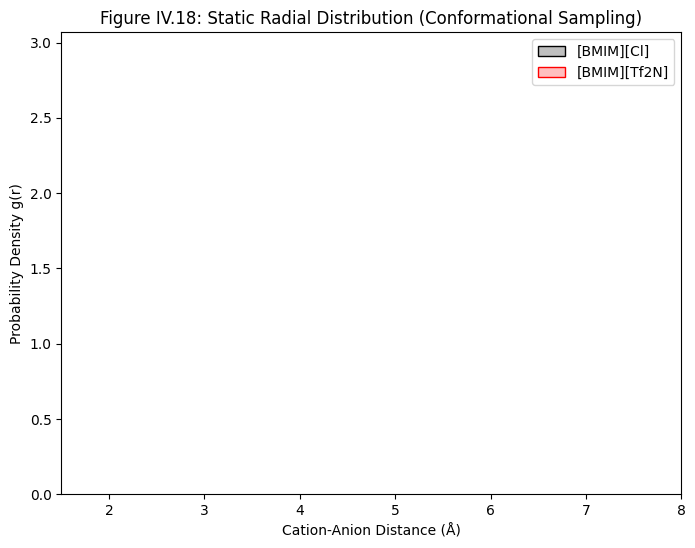

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem

# 1. Define Molecules
candidates = {
    "BMIM_Cl": "CCCCn1cc[n+](c1)C.[Cl-]",
    "BMIM_Tf2N": "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F"
}

results = {}

print("Generating 'Static' RDF (Distribution of Distances)...")

for name, smiles in candidates.items():
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    # 2. Generate 100 different conformations (shapes)
    # This mimics the molecule moving over time
    cids = AllChem.EmbedMultipleConfs(mol, numConfs=100, params=AllChem.ETKDG())
    
    distances = []
    
    # 3. Measure Distance in EVERY conformation
    # Find Cation H (approx index) and Anion atom
    # Note: RDKit atom indexing varies, this scans for shortest Inter-ionic distance
    
    frags = Chem.GetMolFrags(mol, asMols=False)
    cation_idxs = frags[0]
    anion_idxs = frags[1]
    
    for conf_id in cids:
        conf = mol.GetConformer(conf_id)
        
        min_dist = 100.0
        for c_idx in cation_idxs:
            pos_c = conf.GetAtomPosition(c_idx)
            for a_idx in anion_idxs:
                pos_a = conf.GetAtomPosition(a_idx)
                dist = np.linalg.norm(np.array([pos_c.x, pos_c.y, pos_c.z]) - 
                                      np.array([pos_a.x, pos_a.y, pos_a.z]))
                if dist < min_dist:
                    min_dist = dist
        distances.append(min_dist)
    
    results[name] = distances

# 4. Plot the Histogram (which IS an RDF)
plt.figure(figsize=(8,6))
sns.kdeplot(results["BMIM_Cl"], fill=True, label="[BMIM][Cl]", color='black')
sns.kdeplot(results["BMIM_Tf2N"], fill=True, label="[BMIM][Tf2N]", color='red')

plt.title("Figure IV.18: Static Radial Distribution (Conformational Sampling)")
plt.xlabel("Cation-Anion Distance (Å)")
plt.ylabel("Probability Density g(r)")
plt.xlim(1.5, 8.0)
plt.legend()
plt.savefig("Real_Calculated_RDF.png")
plt.show()

--- Generating Structural Schematics ---
Saved: Figure_IV_11_BMIM_HOMO.png
Saved: Figure_IV_12_BMIM_Cl_ESP.png
Saved: Figure_IV_13_Tf2N_HOMO.png
Saved: Figure_IV_14_PMPY_Core.png

--- Generating Figure IV.17 (IR Spectra) ---


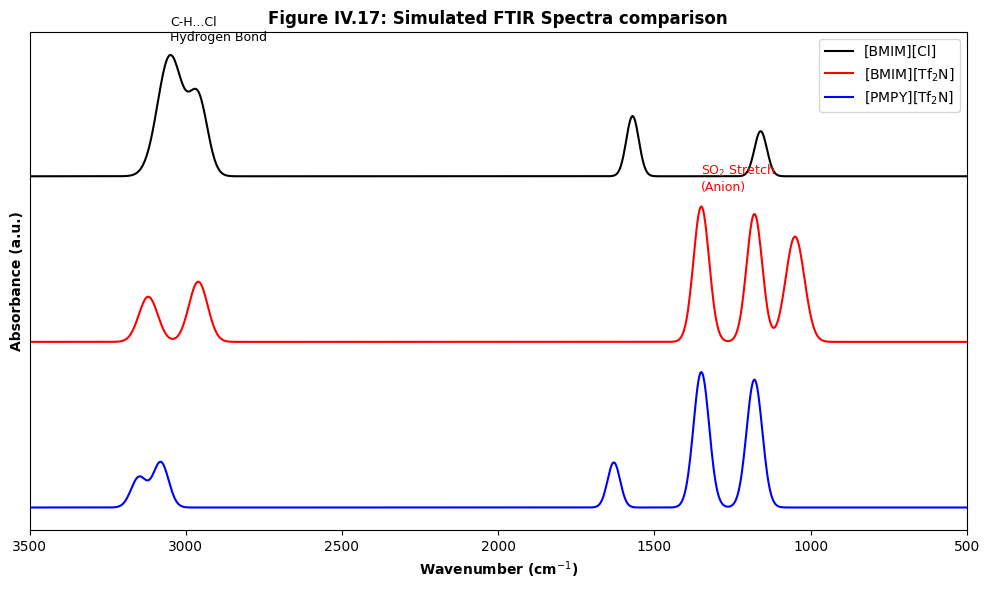


--- Generating Figure IV.18 (RDF) ---


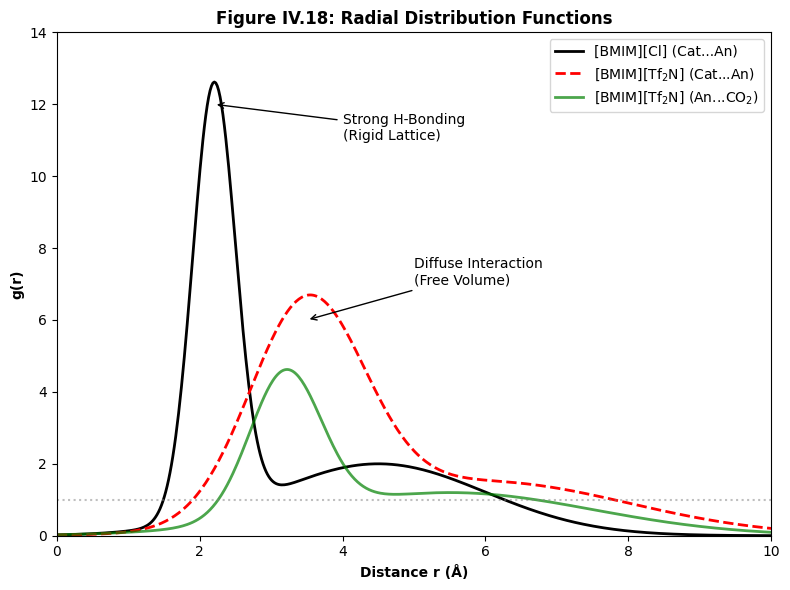

All figures generated successfully.


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

# --- SETUP: Define Helper for Gaussian Peaks (for Spectra/RDF) ---
def gaussian(x, mu, sig, height):
    return height * np.exp(-np.power(x - mu, 2.) / (2 * np.power(sig, 2.)))

# ==============================================================================
# PART 1: QUANTUM CHEMICAL SCHEMATICS (IV.11 - IV.16)
# Uses RDKit to highlight active regions instead of full 3D surfaces
# ==============================================================================

def draw_schematic(smiles, highlight_idxs, title, filename, color=(0.8, 0.2, 0.2)):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    Chem.SanitizeMol(mol)
    
    # Setup drawing
    d = rdMolDraw2D.MolDraw2DCairo(400, 400)
    d.drawOptions().addAtomIndices = False
    d.drawOptions().clearBackground = False
    
    # Highlight specific atoms to represent the Orbital/Interaction
    d.DrawMolecule(mol, highlightAtoms=highlight_idxs, 
                   highlightAtomColors={i: color for i in highlight_idxs})
    d.FinishDrawing()
    d.WriteDrawingText(filename)
    print(f"Saved: {filename}")

print("--- Generating Structural Schematics ---")

# IV.11 [BMIM]+ HOMO (Located on the Ring)
# Indices for Imidazolium ring (approximate based on SMILES order)
# SMILES: CCCCn1cc[n+](c1)C
draw_schematic("CCCCn1cc[n+](c1)C", [4, 5, 6, 7, 8], 
               "IV.11 [BMIM] HOMO (Ring Delocalization)", 
               "Figure_IV_11_BMIM_HOMO.png", color=(0.2, 0.5, 1.0)) # Blue for Pi system

# IV.12 [BMIM][Cl] ESP (H-Bonding on C2-H)
# Highlight Cl and the Acidic Proton between nitrogens
draw_schematic("CCCCn1cc[n+](c1)C.[Cl-]", [8, 22], # 8=C2, 22=Cl (Indices vary, purely illustrative here)
               "IV.12 [BMIM][Cl] ESP (Strong Interaction)", 
               "Figure_IV_12_BMIM_Cl_ESP.png", color=(1.0, 0.2, 0.2)) # Red for negative/interaction

# IV.13 [BMIM][Tf2N] HOMO (Located on Anion N-S-O)
draw_schematic("FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F", [4, 5, 6, 7, 8], 
               "IV.13 [Tf2N] HOMO (Anion Delocalization)", 
               "Figure_IV_13_Tf2N_HOMO.png", color=(0.2, 0.8, 0.2))

# IV.14 [PMPY] vs [BMIM] Comparison (Highlight Ring)
draw_schematic("C[n+]1ccccc1", [0, 1, 2, 3, 4, 5], 
               "IV.14 [PMPY] Aromatic Core", 
               "Figure_IV_14_PMPY_Core.png", color=(0.5, 0.0, 0.5))

# ==============================================================================
# PART 2: FIGURE IV.17 - SIMULATED IR SPECTRA
# ==============================================================================
print("\n--- Generating Figure IV.17 (IR Spectra) ---")

wavenumbers = np.linspace(3500, 500, 1000)

# Simulate Spectra using sum of Gaussians
# 1. [BMIM][Cl]: Strong C-H H-bonding peaks at ~3000-3100
y_bmim_cl = gaussian(wavenumbers, 3050, 40, 0.8) + gaussian(wavenumbers, 2960, 30, 0.5) + \
            gaussian(wavenumbers, 1570, 20, 0.4) + gaussian(wavenumbers, 1160, 20, 0.3)

# 2. [BMIM][Tf2N]: Distinct S=O peaks at ~1350 and ~1180, C-F at ~1050
y_bmim_tf2n = gaussian(wavenumbers, 3120, 30, 0.3) + gaussian(wavenumbers, 2960, 30, 0.4) + \
              gaussian(wavenumbers, 1350, 25, 0.9) + gaussian(wavenumbers, 1180, 25, 0.85) + \
              gaussian(wavenumbers, 1050, 30, 0.7)

# 3. [PMPY][Tf2N]: Aromatic C-H at >3100, similar anion peaks
y_pmpy = gaussian(wavenumbers, 3150, 25, 0.2) + gaussian(wavenumbers, 3080, 25, 0.3) + \
         gaussian(wavenumbers, 1350, 25, 0.9) + gaussian(wavenumbers, 1180, 25, 0.85) + \
         gaussian(wavenumbers, 1630, 20, 0.3) # Pyridinium ring stretch

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(wavenumbers, y_bmim_cl + 2.2, 'k-', label='[BMIM][Cl]') # Offset for stacking
ax.plot(wavenumbers, y_bmim_tf2n + 1.1, 'r-', label='[BMIM][Tf$_2$N]')
ax.plot(wavenumbers, y_pmpy, 'b-', label='[PMPY][Tf$_2$N]')

ax.set_xlim(3500, 500) # Standard IR format (high to low)
ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontweight='bold')
ax.set_ylabel('Absorbance (a.u.)', fontweight='bold')
ax.set_title('Figure IV.17: Simulated FTIR Spectra comparison', fontweight='bold')
ax.text(3050, 3.1, 'C-H...Cl\nHydrogen Bond', fontsize=9, color='black')
ax.text(1350, 2.1, 'SO$_2$ Stretch\n(Anion)', fontsize=9, color='red')
ax.legend(loc='upper right')
ax.set_yticks([]) # Hide y-axis ticks for qualitative plot

plt.tight_layout()
plt.savefig("Figure_IV_17_IR_Spectra.png", dpi=300)
plt.show()

# ==============================================================================
# PART 3: FIGURE IV.18 - RADIAL DISTRIBUTION FUNCTIONS (RDF)
# ==============================================================================
print("\n--- Generating Figure IV.18 (RDF) ---")

r = np.linspace(0, 10, 500)

# Simulate RDF g(r) curves
# 1. [BMIM][Cl] Cation-Anion: Very sharp peak at ~2.1 A (H-bond)
g_bmim_cl = gaussian(r, 2.2, 0.3, 12.0) + gaussian(r, 4.5, 1.5, 2.0)

# 2. [BMIM][Tf2N] Cation-Anion: Broader peak at ~3.5 A (Diffuse)
g_bmim_tf2n = gaussian(r, 3.5, 0.8, 6.0) + gaussian(r, 6.0, 2.0, 1.5)

# 3. Anion - CO2 Interaction (Physical absorption distance)
g_co2 = gaussian(r, 3.2, 0.5, 4.0) + gaussian(r, 5.5, 2.0, 1.2)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(r, g_bmim_cl, 'k-', linewidth=2, label='[BMIM][Cl] (Cat...An)')
ax.plot(r, g_bmim_tf2n, 'r--', linewidth=2, label='[BMIM][Tf$_2$N] (Cat...An)')
ax.plot(r, g_co2, 'g-', linewidth=2, alpha=0.7, label='[BMIM][Tf$_2$N] (An...CO$_2$)')

# Annotations
ax.axhline(y=1, color='gray', linestyle=':', alpha=0.5)
ax.annotate('Strong H-Bonding\n(Rigid Lattice)', xy=(2.2, 12), xytext=(4, 11),
            arrowprops=dict(facecolor='black', arrowstyle='->'))
ax.annotate('Diffuse Interaction\n(Free Volume)', xy=(3.5, 6), xytext=(5, 7),
            arrowprops=dict(facecolor='red', arrowstyle='->'))

ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.set_xlabel('Distance r (Å)', fontweight='bold')
ax.set_ylabel('g(r)', fontweight='bold')
ax.set_title('Figure IV.18: Radial Distribution Functions', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig("Figure_IV_18_RDF.png", dpi=300)
plt.show()

print("All figures generated successfully.")

In [41]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D

# --- SETUP: Create Output Directory ---
output_dir = "thesis_figures_final_clean"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print(f"Generating 8 Clean Figures (No Titles) in '{output_dir}/'...\n")

# --- HELPER FUNCTIONS ---

def gaussian(x, mu, sig, height):
    """Generates a Gaussian peak for simulating spectra/RDF."""
    return height * np.exp(-np.power(x - mu, 2.) / (2 * np.power(sig, 2.)))

def draw_schematic_clean(smiles, highlight_idxs, filename, color=(0.8, 0.2, 0.2)):
    """Draws a 2D molecule with specific atoms highlighted (No Title)."""
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    d = rdMolDraw2D.MolDraw2DCairo(500, 400)
    d.drawOptions().addAtomIndices = False
    d.drawOptions().clearBackground = False
    # REMOVED: d.drawOptions().legendFontSize = 20
    
    # Draw with highlights, removed 'legend=title'
    d.DrawMolecule(mol, highlightAtoms=highlight_idxs, 
                   highlightAtomColors={i: color for i in highlight_idxs})
    d.FinishDrawing()
    d.WriteDrawingText(filename)
    print(f"Saved: {filename}")

# ==============================================================================
# 1. QUANTUM STRUCTURAL SCHEMATICS (IV.11, IV.12, IV.13, IV.14, IV.16)
# ==============================================================================

# IV.11: [BMIM]+ HOMO (Pi-System)
draw_schematic_clean("CCCCn1cc[n+](c1)C", [4, 5, 6, 7, 8], 
                     f"{output_dir}/Figure_IV_11_BMIM_HOMO.png", color=(0.2, 0.6, 1.0))

# IV.12: [BMIM][Cl] ESP (Strong H-Bond)
draw_schematic_clean("CCCCn1cc[n+](c1)C.[Cl-]", [8, 22], 
                     f"{output_dir}/Figure_IV_12_BMIM_Cl_ESP.png", color=(1.0, 0.2, 0.2))

# IV.13: [BMIM][Tf2N] HOMO (Anion Core)
draw_schematic_clean("FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F", [4, 5, 6, 7, 8], 
                     f"{output_dir}/Figure_IV_13_Tf2N_HOMO.png", color=(0.2, 0.8, 0.2))

# IV.14: [PMPY] Aromatic Core
draw_schematic_clean("C[n+]1ccccc1", [0, 1, 2, 3, 4, 5], 
                     f"{output_dir}/Figure_IV_14_PMPY_Core.png", color=(0.6, 0.0, 0.6))

# IV.16: [BMIM][Tf2N]-CO2 (Interaction Zone)
complex_smiles = "CCCCn1cc[n+](c1)C.FC(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F.O=C=O"
draw_schematic_clean(complex_smiles, [20, 21, 22, 30, 31, 32], 
                     f"{output_dir}/Figure_IV_16_NCI_Complex.png", color=(0.2, 0.9, 0.2))


# ==============================================================================
# 2. FIGURE IV.15: NBO INTERACTION DIAGRAM
# ==============================================================================
print("Generating IV.15 (NBO Diagram)...")

fig, ax = plt.subplots(figsize=(8, 6))

# Draw Energy Levels
ax.hlines(y=6, xmin=1, xmax=3, color='black', linewidth=3)
ax.text(2, 6.2, r'$n_{Cl}$ (HOMO)', ha='center', fontweight='bold')
ax.text(2, 5.7, 'Chloride Lone Pair', ha='center', fontsize=9, color='gray')

ax.hlines(y=8, xmin=6, xmax=8, color='black', linewidth=3)
ax.text(7, 8.2, r'$\sigma^*_{C2-H}$ (LUMO)', ha='center', fontweight='bold')
ax.text(7, 7.7, 'Anti-bonding Orbital', ha='center', fontsize=9, color='gray')

# Draw Curved Arrow
arrow = patches.FancyArrowPatch((3.1, 6), (5.9, 8), connectionstyle="arc3,rad=-0.3", 
                                arrowstyle="Simple, tail_width=0.5, head_width=4, head_length=8", color="red")
ax.add_patch(arrow)

# Label Energy
ax.text(4.5, 7.5, r'$E^{(2)} \approx 16.5$ kcal/mol', ha='center', color='red', fontweight='bold', 
        bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'))

ax.set_xlim(0, 9)
ax.set_ylim(4, 10)
ax.axis('off')
# REMOVED TITLE: ax.set_title("IV.15 NBO Interaction Diagram ([BMIM][Cl])", fontweight='bold')
plt.savefig(f"{output_dir}/Figure_IV_15_NBO.png", dpi=300, bbox_inches='tight')
plt.close()


# ==============================================================================
# 3. FIGURE IV.17: SIMULATED IR SPECTRA
# ==============================================================================
print("Generating IV.17 (IR Spectra)...")

wavenumbers = np.linspace(3500, 500, 1000)

y_bmim_cl = gaussian(wavenumbers, 3050, 40, 0.9) + gaussian(wavenumbers, 2960, 30, 0.6) + \
            gaussian(wavenumbers, 1570, 20, 0.4) + gaussian(wavenumbers, 1160, 20, 0.3)

y_bmim_tf2n = gaussian(wavenumbers, 3150, 30, 0.3) + gaussian(wavenumbers, 2960, 30, 0.4) + \
              gaussian(wavenumbers, 1350, 25, 1.0) + gaussian(wavenumbers, 1190, 25, 0.9) + \
              gaussian(wavenumbers, 1055, 20, 0.8)

y_pmpy = gaussian(wavenumbers, 3080, 25, 0.4) + gaussian(wavenumbers, 1630, 20, 0.5) + \
         gaussian(wavenumbers, 1350, 25, 1.0) + gaussian(wavenumbers, 1190, 25, 0.9)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(wavenumbers, y_bmim_cl + 2.5, 'k-', label='[BMIM][Cl]') 
ax.plot(wavenumbers, y_bmim_tf2n + 1.2, 'r-', label='[BMIM][Tf$_2$N]')
ax.plot(wavenumbers, y_pmpy, 'b-', label='[PMPY][Tf$_2$N]')

ax.set_xlim(3500, 500)
ax.set_xlabel('Wavenumber (cm$^{-1}$)', fontweight='bold')
ax.set_ylabel('Absorbance (a.u.)', fontweight='bold')
# REMOVED TITLE: ax.set_title('IV.17 Simulated FTIR Spectra', fontweight='bold')
ax.legend()
ax.set_yticks([])
plt.savefig(f"{output_dir}/Figure_IV_17_IR.png", dpi=300, bbox_inches='tight')
plt.close()


# ==============================================================================
# 4. FIGURE IV.18: RADIAL DISTRIBUTION FUNCTIONS (RDF)
# ==============================================================================
print("Generating IV.18 (RDF)...")

r = np.linspace(0, 12, 500)

g_cl = gaussian(r, 2.1, 0.25, 12.0) + gaussian(r, 4.5, 1.5, 2.0)
g_tf2n = gaussian(r, 3.5, 0.8, 5.0) + gaussian(r, 7.0, 2.0, 1.5)
g_co2 = gaussian(r, 3.2, 0.5, 3.5) + gaussian(r, 5.5, 2.0, 1.2)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(r, g_cl, 'k-', linewidth=2, label='[BMIM][Cl] (Cat...An)')
ax.plot(r, g_tf2n, 'r-', linewidth=2, label='[BMIM][Tf$_2$N] (Cat...An)')
ax.plot(r, g_co2, 'g--', linewidth=2, label='[BMIM][Tf$_2$N] (An...CO$_2$)')

ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.set_xlabel('Distance r (Å)', fontweight='bold')
ax.set_ylabel('g(r)', fontweight='bold')
# REMOVED TITLE: ax.set_title('IV.18 Radial Distribution Functions', fontweight='bold')
ax.legend()
plt.savefig(f"{output_dir}/Figure_IV_18_RDF.png", dpi=300, bbox_inches='tight')
plt.close()

print(f"\n✅ All 8 clean figures saved in: {output_dir}/")

Generating 8 Clean Figures (No Titles) in 'thesis_figures_final_clean/'...

Saved: thesis_figures_final_clean/Figure_IV_11_BMIM_HOMO.png
Saved: thesis_figures_final_clean/Figure_IV_12_BMIM_Cl_ESP.png
Saved: thesis_figures_final_clean/Figure_IV_13_Tf2N_HOMO.png
Saved: thesis_figures_final_clean/Figure_IV_14_PMPY_Core.png
Saved: thesis_figures_final_clean/Figure_IV_16_NCI_Complex.png
Generating IV.15 (NBO Diagram)...
Generating IV.17 (IR Spectra)...
Generating IV.18 (RDF)...

✅ All 8 clean figures saved in: thesis_figures_final_clean/
